# **Maestría en Inteligencia Artificial Aplicada**

## **Curso: Inteligencia Artificial y Aprendizaje Automático**

**Tecnológico de Monterrey**

**Prof Luis Eduardo Falcón Morales**

### **Actividad de Modelos Regresión para la Predicción de Precios de Casas**

**Integrantes del Equipo:**

* **Nombre y matrícula:** Erick Rojas Pérez · A01840850
* **Nombre y matrícula:** Alejandro Benjamin Rodriguez Mares · A01840836
* **Nombre y matrícula:** Darío Martín Romero Cruz · A01841015


## 0. Configuración del entorno

Este notebook resuelve la actividad completa. Todas las decisiones de preprocesamiento se aprenden **solo con el conjunto de entrenamiento** dentro de `Pipeline`/`ColumnTransformer`, para evitar el filtrado de información (*data leakage*). Las semillas aleatorias están fijas (`RANDOM_STATE = 42`), de modo que los resultados se pueden reproducir. Funciona en Google Colab o en Jupyter local con scikit-learn ≥ 1.4 y XGBoost.

**Dónde se responde cada pregunta**

| Pregunta | Sección |
|---|---|
| 1, 2 y 3 (variables temporales) | 3 y 6 |
| 4 y 5 (limpieza, imputación y transformaciones) | 4 |
| 6 (`drop` en One-Hot-Encoding) | 5 |
| 7 (partición) | 4 |
| 8 (modelo base) | 7 |
| 9 (seis modelos, curvas de aprendizaje y tabla de métricas) | 8 |
| 10 (análisis de factores) | 9 |
| 11 (RMSE + MAE) | 10 |
| 12, 13 y 14 (votación y apilamiento) | 11 |
| 15 (comparación de los ensambles) | 12 |
| 16 (reportes técnico y ejecutivo) | 13 |
| 17 (conclusiones) | Sección «Conclusiones» del final |

In [2]:
import os
import time
import warnings

# Los procesos paralelos de scikit-learn heredan este filtro (avisos de convergencia repetidos por fold)
os.environ.setdefault("PYTHONWARNINGS", "ignore::UserWarning,ignore::FutureWarning")

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import xgboost
from IPython.display import display
from scipy.stats import kruskal
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.datasets import fetch_openml
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor, StackingRegressor, VotingRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, Ridge
from sklearn.metrics import (mean_absolute_error, mean_absolute_percentage_error, r2_score,
                             root_mean_squared_error)
from sklearn.model_selection import (GridSearchCV, KFold, RandomizedSearchCV, RepeatedKFold,
                                     cross_validate, learning_curve, train_test_split)
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import (FunctionTransformer, OneHotEncoder, OrdinalEncoder, PowerTransformer,
                                   StandardScaler)
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="Found unknown categories")

RANDOM_STATE = 42
CURRENT_YEAR = 2026
np.random.seed(RANDOM_STATE)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print(f"scikit-learn {sklearn.__version__} | xgboost {xgboost.__version__} | pandas {pd.__version__} | numpy {np.__version__}")

scikit-learn 1.9.1 | xgboost 3.4.1 | pandas 2.2.2 | numpy 1.26.4


## 1. Carga de datos

Usamos el archivo `train.csv` del reto de Kaggle *House Prices – Advanced Regression Techniques*, que es el único que incluye la variable objetivo `SalePrice` (el `test.csv` de Kaggle no la trae, así que no sirve para evaluar). Si `train.csv` está en la misma carpeta que el notebook, se lee de ahí. Si no, se descarga la copia idéntica que Kaggle publicó en OpenML (conjunto 42165, 1,460 × 81), de modo que el notebook corre en Colab sin credenciales de Kaggle.

Al leer el CSV hay un detalle importante: pandas interpreta por defecto el texto `"None"` como dato faltante, pero en `MasVnrType` «None» es una categoría real (sin chapa de mampostería). Por eso indicamos explícitamente que solo `"NA"` y las celdas vacías son faltantes.

In [3]:
def load_house_prices(path="train.csv"):
    """train.csv de Kaggle si está junto al notebook; si no, la copia idéntica publicada en OpenML (id 42165)."""
    p = Path(path)
    if p.exists():
        # «None» es una categoría real de MasVnrType: evitamos que pandas la lea como dato faltante
        df = pd.read_csv(p, keep_default_na=False, na_values=["NA", ""])
        source = f"archivo local {p.name}"
    else:
        df = fetch_openml(data_id=42165, as_frame=True, parser="auto").frame
        source = "OpenML id 42165 (copia de train.csv de Kaggle)"
    for c in df.columns:
        if not pd.api.types.is_numeric_dtype(df[c]):
            # OpenML encierra entre comillas los valores con espacios ('C (all)'); se dejan igual que en Kaggle
            df[c] = df[c].astype(object).map(lambda v: v.strip("'") if isinstance(v, str) else v)
    return df, source


raw, source = load_house_prices()
assert raw.shape == (1460, 81), raw.shape
assert raw["MasVnrType"].isna().sum() == 8, "MasVnrType='None' se leyó como faltante"
print(f"Fuente: {source} | {raw.shape[0]} casas × {raw.shape[1]} columnas")
raw.head()

Fuente: OpenML id 42165 (copia de train.csv de Kaggle) | 1460 casas × 81 columnas


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,...,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,...,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,None,0.0,TA,TA,CBlock,...,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,...,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,None,0.0,TA,TA,BrkTil,...,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,...,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [4]:
n_num = raw.drop(columns=["Id", "SalePrice"]).select_dtypes("number").shape[1]
n_cat = raw.select_dtypes(exclude="number").shape[1]
print(f"Variables de entrada: {n_num} numéricas y {n_cat} categóricas (sin contar Id ni SalePrice)")
raw["SalePrice"].describe().to_frame().T.round(0)

Variables de entrada: 36 numéricas y 43 categóricas (sin contar Id ni SalePrice)


,count,mean,std,min,25%,50%,75%,max
SalePrice,1460.0,180921.0,79443.0,34900.0,129975.0,163000.0,214000.0,755000.0


## 2. Análisis exploratorio

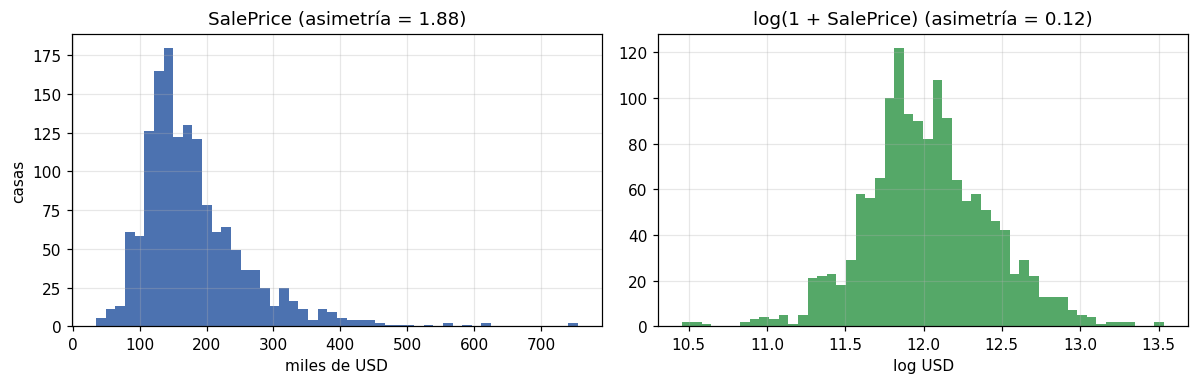

In [5]:
y_raw = raw["SalePrice"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(y_raw / 1000, bins=50, color="#4C72B0")
axes[0].set(title=f"SalePrice (asimetría = {y_raw.skew():.2f})", xlabel="miles de USD", ylabel="casas")
axes[1].hist(np.log1p(y_raw), bins=50, color="#55A868")
axes[1].set(title=f"log(1 + SalePrice) (asimetría = {np.log1p(y_raw).skew():.2f})", xlabel="log USD")
plt.tight_layout()
plt.show()

La variable objetivo tiene una **asimetría positiva fuerte (1.88)**: muchas casas de precio medio y una cola de casas caras. Con el logaritmo la distribución se vuelve casi simétrica (0.12). Por eso todos los modelos aprenden `log(1 + SalePrice)` mediante `TransformedTargetRegressor`, que convierte las predicciones de regreso a dólares para calcular las métricas. Así:

* los errores se vuelven **relativos** (equivocarse por 20,000 USD es grave en una casa de 100,000 y menor en una de 500,000), que es como se negocia el precio de una vivienda;
* la varianza del error deja de crecer con el precio, lo que favorece a los modelos lineales, a la SVR y a la red neuronal;
* **todas las métricas (RMSE, MAE, R², MAPE) se reportan en dólares**, sobre la escala original.

In [6]:
missing = raw.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
structural = {
    "PoolQC": "Sin alberca (PoolArea = 0)", "MiscFeature": "Sin característica extra (MiscVal = 0)",
    "Alley": "Sin acceso a callejón", "Fence": "Sin cerca", "FireplaceQu": "Sin chimenea (Fireplaces = 0)",
    "GarageType": "Sin garaje (GarageArea = 0)", "GarageFinish": "Sin garaje", "GarageQual": "Sin garaje",
    "GarageCond": "Sin garaje", "GarageYrBlt": "Sin garaje (variable de año, se elimina)",
    "BsmtQual": "Sin sótano (TotalBsmtSF = 0)", "BsmtCond": "Sin sótano", "BsmtFinType1": "Sin sótano",
    "BsmtExposure": "37 sin sótano + 1 faltante real", "BsmtFinType2": "37 sin sótano + 1 faltante real",
}
missing_table = pd.DataFrame({
    "faltantes": missing,
    "% del total": (100 * missing / len(raw)).round(1),
    "interpretación": [structural.get(c, "Faltante real (se imputa)") for c in missing.index],
})
missing_table

,faltantes,% del total,interpretación
PoolQC,1453,99.5,Sin alberca (PoolArea = 0)
MiscFeature,1406,96.3,Sin característica extra (MiscVal = 0)
Alley,1369,93.8,Sin acceso a callejón
Fence,1179,80.8,Sin cerca
FireplaceQu,690,47.3,Sin chimenea (Fireplaces = 0)
LotFrontage,259,17.7,Faltante real (se imputa)
GarageType,81,5.5,Sin garaje (GarageArea = 0)
GarageYrBlt,81,5.5,"Sin garaje (variable de año, se elimina)"
GarageFinish,81,5.5,Sin garaje
GarageQual,81,5.5,Sin garaje


In [7]:
checks = pd.DataFrame({
    "NA en la variable": [raw.PoolQC.isna().sum(), raw.GarageType.isna().sum(), raw.BsmtQual.isna().sum(),
                          raw.FireplaceQu.isna().sum(), raw.MiscFeature.isna().sum()],
    "NA y área/conteo = 0": [(raw.PoolQC.isna() & raw.PoolArea.eq(0)).sum(),
                             (raw.GarageType.isna() & raw.GarageArea.eq(0) & raw.GarageCars.eq(0)).sum(),
                             (raw.BsmtQual.isna() & raw.TotalBsmtSF.eq(0)).sum(),
                             (raw.FireplaceQu.isna() & raw.Fireplaces.eq(0)).sum(),
                             (raw.MiscFeature.isna() & raw.MiscVal.eq(0)).sum()],
}, index=["PoolQC vs PoolArea", "GarageType vs GarageArea y GarageCars", "BsmtQual vs TotalBsmtSF",
          "FireplaceQu vs Fireplaces", "MiscFeature vs MiscVal"])
checks

,NA en la variable,NA y área/conteo = 0
PoolQC vs PoolArea,1453,1453
GarageType vs GarageArea y GarageCars,81,81
BsmtQual vs TotalBsmtSF,37,37
FireplaceQu vs Fireplaces,690,690
MiscFeature vs MiscVal,1406,1406


Las tablas muestran que **la mayoría de los «faltantes» no lo son**. Según el diccionario de datos de Kaggle, `NA` en `PoolQC`, `MiscFeature`, `Alley`, `Fence`, `FireplaceQu`, las variables `Garage*` y las variables `Bsmt*` significa que **la casa no tiene** esa característica. Lo comprobamos con la variable numérica asociada: los 1,453 `PoolQC` vacíos tienen `PoolArea = 0`, los 81 `GarageType` vacíos tienen `GarageArea = 0` y `GarageCars = 0`, y los 37 `BsmtQual` vacíos tienen `TotalBsmtSF = 0`. Solo quedan unos cuantos faltantes reales: `LotFrontage` (259), `MasVnrType` y `MasVnrArea` (8), `Electrical` (1), `BsmtExposure` y `BsmtFinType2` (1 cada una, en casas que sí tienen sótano).

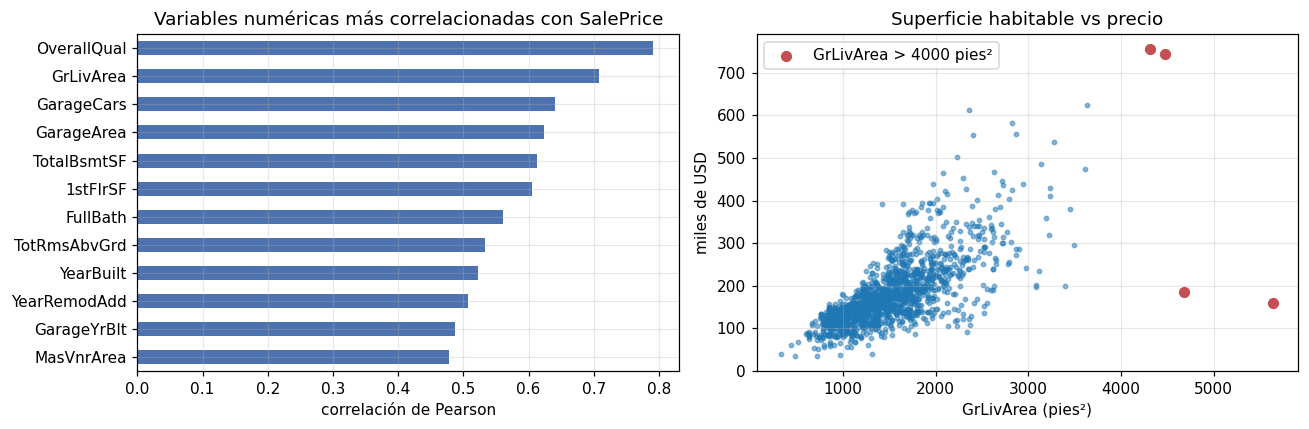

,Id,GrLivArea,SalePrice,SaleCondition,Neighborhood
523,524,4676,184750,Partial,Edwards
691,692,4316,755000,Normal,NoRidge
1182,1183,4476,745000,Abnorml,NoRidge
1298,1299,5642,160000,Partial,Edwards


In [8]:
corr = raw.drop(columns="Id").select_dtypes("number").corr()["SalePrice"].drop("SalePrice").sort_values()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
corr.tail(12).plot.barh(ax=axes[0], color="#4C72B0")
axes[0].set(title="Variables numéricas más correlacionadas con SalePrice", xlabel="correlación de Pearson")
big = raw.GrLivArea > 4000
axes[1].scatter(raw.GrLivArea, raw.SalePrice / 1000, s=8, alpha=0.5)
axes[1].scatter(raw.GrLivArea[big], raw.SalePrice[big] / 1000, s=40, color="#C44E52", label="GrLivArea > 4000 pies²")
axes[1].set(title="Superficie habitable vs precio", xlabel="GrLivArea (pies²)", ylabel="miles de USD")
axes[1].legend()
plt.tight_layout()
plt.show()
raw.loc[big, ["Id", "GrLivArea", "SalePrice", "SaleCondition", "Neighborhood"]]

La calidad general (`OverallQual`) y la superficie habitable (`GrLivArea`) son las variables más asociadas con el precio. En la gráfica de dispersión aparecen cuatro casas de más de 4,000 pies². Dos de ellas son ventas parciales (`Partial`) en Edwards con precios anómalamente bajos para su tamaño, y las otras dos son residencias de lujo en NoRidge. El autor del conjunto de datos, De Cock (2011), recomienda excluir las casas de más de 4,000 pies² porque son atípicas y no representan el mercado que se quiere modelar. Seguimos esa recomendación como **regla de alcance**: el modelo valúa casas de hasta 4,000 pies². La regla depende solo de `GrLivArea`, no del precio, así que no introduce información de la variable objetivo.

## 3. Restricciones temporales (preguntas 1, 2 y 3)

El problema simula una valuación **estática**: el modelo debe estimar el valor de una casa por sus características, no por el momento en que se vendió. Las variables de calendario absoluto (2006–2010) describen **cuándo** ocurrió la transacción, y ese contexto no se repetirá cuando el modelo se use en 2026.

In [9]:
by_year = raw.groupby("YrSold")["SalePrice"].agg(casas="count", mediana="median", media="mean").round(0)
p_year = kruskal(*[g.SalePrice.values for _, g in raw.groupby("YrSold")]).pvalue
print(f"Kruskal-Wallis del precio por YrSold: p = {p_year:.3f} | corr(YrSold, SalePrice) = {raw.YrSold.corr(raw.SalePrice):.3f}")
by_year

Kruskal-Wallis del precio por YrSold: p = 0.801 | corr(YrSold, SalePrice) = -0.029


,casas,mediana,media
YrSold,,,
2006,314,163995.0,182549.0
2007,329,167000.0,186063.0
2008,304,164000.0,177361.0
2009,338,162000.0,179432.0
2010,175,155000.0,177394.0


### Pregunta 1. Decisión sobre `YrSold`: se elimina

* **Es una tendencia cronológica absoluta.** Las ventas ocurrieron entre 2006 y 2010, un periodo que incluye la crisis hipotecaria de 2008. Si el modelo usara el año de venta, aprendería el ciclo económico de esos años y no el valor de la propiedad.
* **No se puede extrapolar.** Al valuar una casa en 2026, `YrSold = 2026` quedaría fuera del rango de entrenamiento. Un modelo lineal extrapolaría la tendencia sin fundamento y un árbol trataría 2026 como si fuera 2010. Las dos cosas son incorrectas.
* **Además, aporta muy poco.** La mediana del precio cambia poco entre años, de 155,000 a 167,000 USD (2010 solo tiene ventas hasta julio). La prueba de Kruskal-Wallis no detecta diferencias (p = 0.80) y la correlación con el precio es de −0.03.

Por todo esto se elimina `YrSold`. Su efecto se incorpora de forma correcta a través de la edad de la casa (pregunta 2).

In [10]:
ages = pd.DataFrame({
    "AgeHouse": CURRENT_YEAR - raw.YearBuilt,
    "AgeRemod": CURRENT_YEAR - raw.YearRemodAdd,
})
print("corr(AgeHouse, YearBuilt)   =", round(ages.AgeHouse.corr(raw.YearBuilt), 6))
print("corr(AgeRemod, YearRemodAdd) =", round(ages.AgeRemod.corr(raw.YearRemodAdd), 6))
print(f"Casas nunca remodeladas (YearRemodAdd = YearBuilt): {(raw.YearRemodAdd == raw.YearBuilt).mean():.1%}")
print(f"YearRemodAdd = 1950 (valor mínimo registrado): {(raw.YearRemodAdd == 1950).sum()} casas")
print(f"GarageYrBlt = YearBuilt en {(raw.GarageYrBlt == raw.YearBuilt).mean():.1%} de las casas; "
      f"corr = {raw.GarageYrBlt.corr(raw.YearBuilt):.3f}; faltante en {raw.GarageYrBlt.isna().sum()} casas sin garaje")
ages.describe().round(1)

corr(AgeHouse, YearBuilt)   = -1.0
corr(AgeRemod, YearRemodAdd) = -1.0
Casas nunca remodeladas (YearRemodAdd = YearBuilt): 52.3%
YearRemodAdd = 1950 (valor mínimo registrado): 178 casas
GarageYrBlt = YearBuilt en 74.6% de las casas; corr = 0.826; faltante en 81 casas sin garaje


,AgeHouse,AgeRemod
count,1460.0,1460.0
mean,54.7,41.1
std,30.2,20.6
min,16.0,16.0
25%,26.0,22.0
50%,53.0,32.0
75%,72.0,59.0
max,154.0,76.0


### Pregunta 2. `YearBuilt` y `YearRemodAdd` → `AgeHouse` y `AgeRemod`

**Decisión.** Creamos `AgeHouse = 2026 − YearBuilt` y `AgeRemod = 2026 − YearRemodAdd`. La edad es una característica **relativa** de la vivienda: refleja el desgaste, la obsolescencia y el estilo constructivo, y se interpreta igual hoy y dentro de cinco años. El año calendario, en cambio, es un dato absoluto que el enunciado pide no usar. La edad mantiene toda la información útil, porque las casas más nuevas y las remodeladas recientemente valen más.

**¿Conservamos las variables originales? No, se eliminan:**

1. `AgeHouse` es una transformación lineal exacta de `YearBuilt` (correlación = −1). Conservar ambas no agrega información.
2. En una regresión lineal causarían **multicolinealidad perfecta**: la matriz XᵀX sería singular y los coeficientes no serían identificables. Incluso con regularización, el efecto se repartiría arbitrariamente entre las dos columnas.
3. En los árboles, dos columnas equivalentes compiten por las mismas divisiones y diluyen la importancia de la variable.
4. Conservar el año original violaría la restricción de no usar variables cronológicas absolutas.

**Decisión adicional: `GarageYrBlt`.** Esta variable es también un año calendario absoluto, así que le aplica la misma restricción. Decidimos **eliminarla** en lugar de convertirla en edad: coincide con `YearBuilt` en el 74.6% de las casas (correlación de 0.83), así que casi no agrega información sobre `AgeHouse`, y falta en las 81 casas sin garaje, donde una «edad del garaje» no tiene sentido.

Notamos también que `YearRemodAdd` tiene un piso artificial en 1950: 178 casas, casi todas construidas antes de ese año, aparecen remodeladas justo en 1950. Esto se debe a cómo se registró el dato. Por eso `AgeRemod` es una medida aproximada de qué tan reciente es la última renovación.

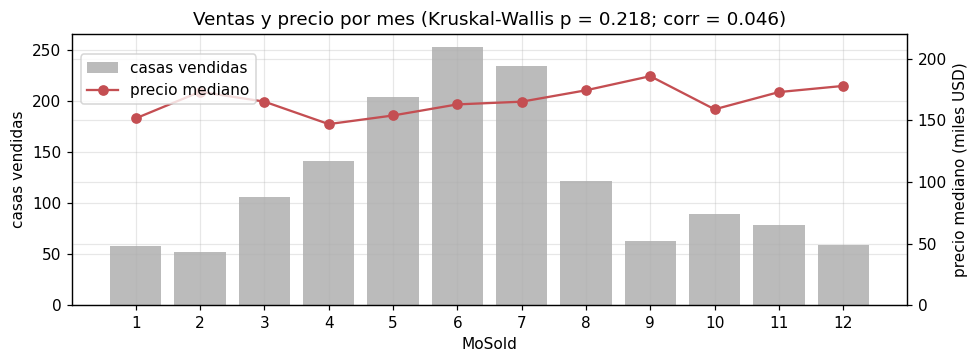

In [11]:
by_month = raw.groupby("MoSold")["SalePrice"].agg(casas="count", mediana="median")
p_month = kruskal(*[g.SalePrice.values for _, g in raw.groupby("MoSold")]).pvalue
fig, ax1 = plt.subplots(figsize=(9, 3.4))
ax1.bar(by_month.index, by_month.casas, color="#BBBBBB", label="casas vendidas")
ax1.set(xlabel="MoSold", ylabel="casas vendidas", xticks=range(1, 13))
ax2 = ax1.twinx()
ax2.plot(by_month.index, by_month.mediana / 1000, "o-", color="#C44E52", label="precio mediano")
ax2.set(ylabel="precio mediano (miles USD)", ylim=(0, 220))
ax1.set_title(f"Ventas y precio por mes (Kruskal-Wallis p = {p_month:.3f}; corr = {raw.MoSold.corr(raw.SalePrice):.3f})")
fig.legend(loc="upper left", bbox_to_anchor=(0.08, 0.86))
plt.tight_layout()
plt.show()

El volumen de ventas es claramente estacional (picos en mayo, junio y julio), pero **el precio no**: la mediana mensual oscila sin un patrón, la prueba de Kruskal-Wallis no encuentra diferencias significativas y la correlación lineal es casi nula. La decisión final sobre `MoSold` se toma con el experimento de la sección 6.

## 4. Limpieza, ingeniería de variables y partición (preguntas 4, 5 y 7)

In [12]:
QUALITY = ["None", "Po", "Fa", "TA", "Gd", "Ex"]
ORDINAL_LEVELS = {
    "ExterQual": QUALITY, "ExterCond": QUALITY, "BsmtQual": QUALITY, "BsmtCond": QUALITY,
    "HeatingQC": QUALITY, "KitchenQual": QUALITY, "FireplaceQu": QUALITY, "GarageQual": QUALITY,
    "GarageCond": QUALITY, "PoolQC": QUALITY,
    "BsmtExposure": ["None", "No", "Mn", "Av", "Gd"],
    "BsmtFinType1": ["None", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    "BsmtFinType2": ["None", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    "GarageFinish": ["None", "Unf", "RFn", "Fin"],
    "Functional": ["Sal", "Sev", "Maj2", "Maj1", "Mod", "Min2", "Min1", "Typ"],
    "PavedDrive": ["N", "P", "Y"],
    "CentralAir": ["N", "Y"],
    "LotShape": ["IR3", "IR2", "IR1", "Reg"],
    "LandSlope": ["Sev", "Mod", "Gtl"],
}
GARAGE_CAT = ["GarageType", "GarageFinish", "GarageQual", "GarageCond"]
BSMT_CAT = ["BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2"]


def fill_structural_na(df):
    """NA que en el diccionario de datos significa «no existe» → categoría 'None'. Regla por fila, sin estadísticas."""
    df = df.copy()
    absent = {
        "PoolQC": df.PoolArea.eq(0),
        "MiscFeature": df.MiscVal.eq(0),
        "Alley": pd.Series(True, index=df.index),
        "Fence": pd.Series(True, index=df.index),
        "FireplaceQu": df.Fireplaces.eq(0),
        **{c: df.GarageArea.fillna(0).eq(0) for c in GARAGE_CAT},
        **{c: df.TotalBsmtSF.fillna(0).eq(0) for c in BSMT_CAT},
    }
    for col, mask in absent.items():
        df.loc[df[col].isna() & mask, col] = "None"
    return df


def prepare(df):
    """Transformaciones fila por fila (no aprenden nada de los datos, así que no hay fuga de información)."""
    df = fill_structural_na(df)
    df["AgeHouse"] = CURRENT_YEAR - df["YearBuilt"]
    df["AgeRemod"] = CURRENT_YEAR - df["YearRemodAdd"]
    df["TotalSF"] = df["TotalBsmtSF"] + df["1stFlrSF"] + df["2ndFlrSF"]
    df["TotalBath"] = df["FullBath"] + 0.5 * df["HalfBath"] + df["BsmtFullBath"] + 0.5 * df["BsmtHalfBath"]
    df["TotalPorchSF"] = df[["WoodDeckSF", "OpenPorchSF", "EnclosedPorch", "3SsnPorch", "ScreenPorch"]].sum(axis=1)
    df["MSSubClass"] = df["MSSubClass"].astype(str).astype(object)  # código de tipo de vivienda: nominal, no numérico
    df = df.drop(columns=["Id", "YrSold", "YearBuilt", "YearRemodAdd", "GarageYrBlt", "Utilities"])
    numeric = df.select_dtypes("number").columns
    df[numeric] = df[numeric].astype(float)  # tipo uniforme (lo requieren las gráficas de dependencia parcial)
    return df


in_scope = raw["GrLivArea"] <= 4000
data = prepare(raw.loc[in_scope])
print(f"Casas fuera del alcance (GrLivArea > 4000 pies²): {(~in_scope).sum()} | casas analizadas: {len(data)}")
remaining = data.isna().sum()
print("Faltantes reales que se imputarán dentro del pipeline:", remaining[remaining > 0].to_dict())

Casas fuera del alcance (GrLivArea > 4000 pies²): 4 | casas analizadas: 1456
Faltantes reales que se imputarán dentro del pipeline: {'LotFrontage': 259, 'MasVnrType': 8, 'MasVnrArea': 8, 'BsmtExposure': 1, 'BsmtFinType2': 1, 'Electrical': 1}


### Pregunta 4. Análisis y procesamiento de los datos: decisiones y justificación

Separamos el preprocesamiento en dos tipos de pasos. Los que se aplican **fila por fila**, sin aprender nada del conjunto (la función `prepare`), se pueden hacer antes de partir los datos. Los que **aprenden estadísticas** (medianas, modas, parámetros de Yeo-Johnson, medias y desviaciones) van dentro del pipeline y se ajustan solo con los datos de entrenamiento de cada fold.

| Decisión | Qué hicimos | Justificación |
|---|---|---|
| Alcance | Excluir 4 casas con `GrLivArea > 4000` | Recomendación del autor del conjunto (De Cock, 2011): son ventas atípicas. La regla no usa el precio. |
| Identificadores | Eliminar `Id` | No describe la vivienda. |
| Variables casi constantes | Eliminar `Utilities` | 1,459 de 1,460 casas tienen el mismo valor, así que no aporta información. |
| Tiempo | Eliminar `YrSold`, `YearBuilt`, `YearRemodAdd` y `GarageYrBlt`; crear `AgeHouse` y `AgeRemod` | Restricción de valuación estática (preguntas 1 y 2). |
| `MSSubClass` | Convertir a texto (nominal) | Es un código de tipo de vivienda: 60 no es «el triple» de 20. |
| NA estructurales | Rellenar con la categoría `"None"` en 14 variables | En el diccionario de datos, NA significa «no tiene». Lo confirmamos con la variable asociada (sección 2). No es un dato perdido, así que no se imputa con media, mediana ni moda. |
| Faltantes reales numéricos | **Mediana** (`LotFrontage`, `MasVnrArea`) | Las distribuciones son asimétricas (`LotFrontage` llega a 313 pies), y la mediana es robusta a valores extremos, a diferencia de la media. La mediana de `MasVnrArea` es 0, lo cual es coherente con «sin chapa». |
| Faltantes reales categóricos | **Moda** (`MasVnrType`, `Electrical`, `BsmtExposure`, `BsmtFinType2`) | Son pocos casos (1 a 8). La moda es la categoría más probable y en `MasVnrType` es «None», coherente con un área de 0. |
| Ingeniería de variables | `TotalSF` (sótano + 1.er piso + 2.º piso), `TotalBath` (baños completos + ½ × medios baños) y `TotalPorchSF` (suma de porches y terraza) | Resumen el tamaño total, que es la principal palanca del precio, y ayudan sobre todo a los modelos lineales. |
| Variables ordinales | `OrdinalEncoder` con orden explícito en 19 variables (escalas Po < Fa < TA < Gd < Ex; `None` = nivel más bajo) | Conserva el orden de la escala de calidad en una sola columna, en lugar de 5 o 6 columnas *dummy* sin orden. |
| Variables nominales | `OneHotEncoder` agrupando categorías con menos de 10 casas (`min_frequency = 10`) | Evita columnas con 1 o 2 casas, que provocan sobreajuste, y maneja categorías nuevas en producción como «infrecuentes». |
| Variables numéricas (lineales, MLP y SVR) | Yeo-Johnson + estandarización + recorte a ±6 desviaciones estándar | Muchas son asimétricas (`LotArea`, `GrLivArea`, áreas de porche). Yeo-Johnson admite ceros, a diferencia de Box-Cox o del logaritmo, y deja las variables en una escala comparable, algo necesario para la regularización, las distancias del kernel RBF y el gradiente de la red. El recorte es una salvaguarda que agregamos al revisar las curvas de aprendizaje: cuando Yeo-Johnson se ajusta con pocas casas, en variables casi siempre en cero (`PoolArea`, `3SsnPorch`, `BsmtHalfBath`) estima λ extremos (por ejemplo, −23.6 para `PoolArea` con 150 casas) y una casa con alberca en validación recibía un valor transformado de más de 12 desviaciones, lo que disparaba la predicción. El recorte solo actúa sobre valores extremos (más de +/-6 desviaciones), así que no altera a la gran mayoría de las casas y acota las predicciones ante casas atípicas en producción. |
| Variables numéricas (árboles) | Solo imputación | Los árboles son invariantes a transformaciones monótonas: escalar no cambia sus divisiones. |
| Variable objetivo | `log(1 + SalePrice)` estandarizado, revertido a dólares | Asimetría de 1.88 → 0.12; los errores pasan a ser relativos (sección 2). Como salvaguarda, al regresar a dólares la predicción se acota a 10 millones de USD (13 veces la casa más cara del conjunto), para que un modelo inestable no produzca valores infinitos. |
| Prevención de fugas | Todo lo que aprende estadísticas está dentro del `Pipeline` | En cada fold de validación cruzada, la imputación, la codificación y el escalado se ajustan sin ver los datos de validación ni de prueba. |

### Pregunta 5. Faltantes de `PoolQC` y `GarageType`

* **`PoolQC` (1,453 de 1,460 vacíos, 99.5%).** No son datos perdidos: las 1,453 casas tienen `PoolArea = 0`, es decir, **no tienen alberca**. Imputarlas con la moda («Gd») inventaría 1,453 albercas de buena calidad, y la media o la mediana no aplican a una variable categórica. Las rellenamos con la categoría `"None"`, que en la escala ordinal vale 0 (Po = 1 … Ex = 5), y así la variable queda como «calidad de la alberca, 0 si no hay». Consideramos eliminarla porque solo 7 casas tienen alberca, pero no estorba: los modelos regularizados y los árboles casi no la usan, y codificada de esta forma no introduce ruido.
* **`GarageType` (81 vacíos, 5.5%).** Las 81 casas tienen `GarageArea = 0` y `GarageCars = 0`: **no tienen garaje**. Imputar con la moda («Attchd», garaje adosado) contradiría las variables numéricas de la misma fila. Las rellenamos con `"None"`, que se convierte en una columna *one-hot* propia. Es una categoría con información real, porque no tener garaje reduce el precio. La misma regla se aplica a `GarageFinish`, `GarageQual` y `GarageCond`, para que las cuatro variables del garaje sean coherentes entre sí.

In [13]:
TARGET = "SalePrice"
X = data.drop(columns=TARGET)
y = data[TARGET]
ordinal_cols = [c for c in ORDINAL_LEVELS if c in X]
nominal_cols = [c for c in X.columns if not pd.api.types.is_numeric_dtype(X[c]) and c not in ordinal_cols]
numeric_cols = [c for c in X.columns if c not in ordinal_cols + nominal_cols and c != "MoSold"]
print(f"{len(numeric_cols)} numéricas + {len(ordinal_cols)} ordinales + {len(nominal_cols)} nominales + MoSold")
print("Ordinales:", ", ".join(ordinal_cols))
print("Nominales:", ", ".join(nominal_cols))

35 numéricas + 19 ordinales + 24 nominales + MoSold
Ordinales: ExterQual, ExterCond, BsmtQual, BsmtCond, HeatingQC, KitchenQual, FireplaceQu, GarageQual, GarageCond, PoolQC, BsmtExposure, BsmtFinType1, BsmtFinType2, GarageFinish, Functional, PavedDrive, CentralAir, LotShape, LandSlope
Nominales: MSSubClass, MSZoning, Street, Alley, LandContour, LotConfig, Neighborhood, Condition1, Condition2, BldgType, HouseStyle, RoofStyle, RoofMatl, Exterior1st, Exterior2nd, MasVnrType, Foundation, Heating, Electrical, GarageType, Fence, MiscFeature, SaleType, SaleCondition


In [14]:
price_decile = pd.qcut(y, q=10, labels=False)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=price_decile)
CV = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print(f"Entrenamiento: {len(X_train)} casas | Prueba: {len(X_test)} casas")
pd.DataFrame({"train": y_train.describe(), "test": y_test.describe()}).T.round(0)

Entrenamiento: 1164 casas | Prueba: 292 casas


,count,mean,std,min,25%,50%,75%,max
train,1164.0,180502.0,77339.0,34900.0,129900.0,162950.0,213122.0,625000.0
test,292.0,178751.0,74195.0,35311.0,130000.0,163000.0,215000.0,611657.0


### Pregunta 7. Partición de los datos

Usamos **80% para entrenamiento (1,164 casas) y 20% para prueba (292 casas)**, con muestreo **estratificado por deciles del precio** para que la prueba contenga todo el rango del mercado, incluidas las casas caras, que son las que más pesan en el RMSE. Las dos distribuciones resultantes son prácticamente iguales.

En lugar de reservar un tercer bloque fijo de validación, usamos **validación cruzada de 5 folds** (`KFold` con mezcla aleatoria) dentro del entrenamiento para ajustar hiperparámetros y comparar modelos, como permite el enunciado. Con solo 1,456 casas, un bloque fijo de validación de 15–20% (≈ 220-290 casas) daría una estimación muy ruidosa. La validación cruzada aprovecha todos los datos de entrenamiento y, además, da la desviación estándar entre folds. **El conjunto de prueba no se usa para elegir nada**: solo para reportar el desempeño final.

## 5. Preprocesamiento dentro de pipelines (preguntas 4 y 6)

In [15]:
MIN_FREQ = 10  # categorías con menos de 10 casas en el fold de entrenamiento se agrupan como «infrecuentes»
MOSOLD_OPTION = "drop"  # se fija con el experimento de la sección 6


def month_to_cycle(m):
    m = np.asarray(m, dtype=float)
    return np.c_[np.sin(2 * np.pi * (m - 1) / 12), np.cos(2 * np.pi * (m - 1) / 12)]


def cycle_names(transformer, input_features):
    return np.array(["MoSold_sin", "MoSold_cos"])


Z_LIMIT = 6  # valores estandarizados más allá de ±6 desviaciones se recortan


def clip_extremes(Z):
    """Yeo-Johnson ajustado con pocos datos puede dar λ extremos en variables casi siempre en cero
    (PoolArea, 3SsnPorch); una casa fuera de ese rango produciría valores enormes. El recorte lo evita."""
    return np.clip(Z, -Z_LIMIT, Z_LIMIT)


def make_preprocessor(kind, mosold=None):
    """kind='linear': escalado + Yeo-Johnson + OHE con drop='first' (lineales, MLP y SVR).
    kind='tree': sin escalado + OHE completo (árbol, bosque aleatorio y XGBoost)."""
    mosold = MOSOLD_OPTION if mosold is None else mosold
    num, nom, extra = list(numeric_cols), list(nominal_cols), []
    if mosold == "numeric":
        num.append("MoSold")
    elif mosold == "categorical":
        nom.append("MoSold")
    elif mosold == "cyclic":
        extra = [("mes", FunctionTransformer(month_to_cycle, feature_names_out=cycle_names), ["MoSold"])]
    ordinal = OrdinalEncoder(categories=[ORDINAL_LEVELS[c] for c in ordinal_cols],
                             handle_unknown="use_encoded_value", unknown_value=-1)
    if kind == "linear":
        num_pipe = Pipeline([("imputar", SimpleImputer(strategy="median")),
                             ("yeo_johnson", PowerTransformer(method="yeo-johnson", standardize=True)),
                             ("recortar", FunctionTransformer(clip_extremes, feature_names_out="one-to-one"))])
        ord_pipe = Pipeline([("imputar", SimpleImputer(strategy="most_frequent")), ("codificar", ordinal),
                             ("escalar", StandardScaler())])
        drop = "first"
    else:
        num_pipe = SimpleImputer(strategy="median")
        ord_pipe = Pipeline([("imputar", SimpleImputer(strategy="most_frequent")), ("codificar", ordinal)])
        drop = None
    nom_pipe = Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                         ("one_hot", OneHotEncoder(drop=drop, handle_unknown="infrequent_if_exist",
                                                   min_frequency=MIN_FREQ, sparse_output=False))])
    return ColumnTransformer([("num", num_pipe, num), ("ord", ord_pipe, ordinal_cols), ("nom", nom_pipe, nom)] + extra,
                             verbose_feature_names_out=False)


MAX_LOG_PRICE = np.log1p(10_000_000)  # tope de seguridad: ninguna predicción supera 10 millones de USD


def to_dollars(z):
    return np.expm1(np.minimum(z, MAX_LOG_PRICE))


def log_target():
    """El modelo aprende log(1 + precio) estandarizado; las predicciones regresan a dólares."""
    return make_pipeline(FunctionTransformer(np.log1p, inverse_func=to_dollars, check_inverse=False), StandardScaler())


def make_model(estimator, kind, mosold=None):
    return Pipeline([("prep", make_preprocessor(kind, mosold)),
                     ("reg", TransformedTargetRegressor(regressor=estimator, transformer=log_target(),
                                                        check_inverse=False))])


for kind in ["linear", "tree"]:
    Xt = make_preprocessor(kind).fit(X_train).transform(X_train)
    print(f"Preprocesador '{kind}': {Xt.shape[1]} columnas de entrada al modelo")

Preprocesador 'linear': 172 columnas de entrada al modelo
Preprocesador 'tree': 196 columnas de entrada al modelo


Definimos dos preprocesadores: uno para los modelos sensibles a la escala (lineales, MLP y SVR) y otro para los modelos de árboles. Los dos usan las mismas reglas de imputación y la misma codificación ordinal.

### Pregunta 6. El hiperparámetro `drop` de One-Hot-Encoding según el tipo de modelo

**Sí hay que distinguir entre modelos.**

* **Regresión lineal (OLS): `drop='first'` es necesario.** Si se conservan las *k* columnas de una variable con *k* categorías, su suma es siempre 1 y coincide con la columna del intercepto. Eso provoca **multicolinealidad perfecta** (la «trampa de las variables dummy»): XᵀX no es invertible y los coeficientes no son únicos. Al eliminar una categoría, esta se vuelve la referencia y cada coeficiente se interpreta como la diferencia de precio respecto a ella.
* **Regresión regularizada (Ridge, Lasso, Elastic Net): opcional.** La penalización hace que la solución sea única aunque haya colinealidad. Aun así, la categoría que se elimina cambia la referencia y, por tanto, qué contrastes se penalizan. Usamos `drop='first'` en toda la familia lineal por consistencia con OLS.
* **Modelos de árboles (árbol, bosque aleatorio, XGBoost): `drop=None`.** Los árboles no invierten matrices, así que la colinealidad no es un problema. Eliminar una columna los perjudica: para aislar la categoría eliminada el árbol necesita varias divisiones (todas las demás columnas en 0), su importancia queda repartida, y cuando el modelo muestrea columnas (`max_features`, `colsample_bytree`) puede ni siquiera tener disponibles las columnas necesarias. Por eso con árboles conservamos todas las categorías.
* **MLP y SVR:** no tienen un problema de identificabilidad estricto. Les dimos el preprocesador «lineal» (`drop='first'` + escalado) porque necesitan variables en escala comparable, y eliminar la columna redundante reduce ligeramente la dimensión.

En ambos casos usamos `handle_unknown='infrequent_if_exist'`: si en producción aparece una categoría nueva, no provoca un error. Se agrupa como «infrecuente» cuando la variable tiene ese grupo y, si no lo tiene, se codifica con ceros (con `drop='first'` equivale a la categoría de referencia). Por eso el monitoreo del reporte técnico incluye validar el esquema de entrada.

In [16]:
# Diagnóstico de la salvaguarda: Yeo-Johnson ajustado con solo 150 casas (como en las primeras curvas de aprendizaje)
small = X_train[numeric_cols].sample(150, random_state=1)
yj_small = PowerTransformer(method="yeo-johnson").fit(small.fillna(small.median()))
z_all = pd.DataFrame(yj_small.transform(X_train[numeric_cols].fillna(small.median())), columns=numeric_cols)
diag = pd.DataFrame({"λ estimada": yj_small.lambdas_, "máx |z| en el resto de casas": z_all.abs().max().values},
                    index=numeric_cols).sort_values("máx |z| en el resto de casas", ascending=False).head(5)
diag.round(1)

,λ estimada,máx |z| en el resto de casas
PoolArea,-23.6,12.2
LotFrontage,0.6,8.1
LotArea,0.1,8.0
3SsnPorch,-9.2,7.0
LowQualFinSF,-8.9,7.0


## 6. Decisión empírica sobre MoSold (pregunta 3)

In [17]:
rkf = RepeatedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
probe_models = {
    "Ridge (alpha=10)": ("linear", Ridge(alpha=10)),
    "Bosque aleatorio (300 árboles)": ("tree", RandomForestRegressor(n_estimators=300, max_features=0.33,
                                                                      random_state=RANDOM_STATE, n_jobs=1)),
}
rows = []
for option in ["numeric", "drop", "categorical", "cyclic"]:
    for model_name, (kind, est) in probe_models.items():
        scores = -cross_validate(make_model(est, kind, mosold=option), X_train, y_train, cv=rkf,
                                 scoring="neg_root_mean_squared_error", n_jobs=-1)["test_score"]
        rows.append({"opción MoSold": option, "modelo": model_name, "RMSE CV": scores.mean(), "desv.": scores.std()})
mosold_table = pd.DataFrame(rows).pivot(index="opción MoSold", columns="modelo", values=["RMSE CV", "desv."]).round(0)
mosold_table.loc[["numeric", "drop", "categorical", "cyclic"]]

RMSE CV                                           desv.                 
modelo        Bosque aleatorio (300 árboles) Ridge (alpha=10) Bosque aleatorio (300 árboles) Ridge (alpha=10)
opción MoSold                                                                                                
numeric                              25738.0          21053.0                         2250.0           1800.0
drop                                 25508.0          21050.0                         2130.0           1794.0
categorical                          25565.0          21232.0                         2214.0           1750.0
cyclic                               25519.0          21069.0                         2068.0           1775.0

### Pregunta 3. Decisión sobre `MoSold`: se elimina

Comparamos las cuatro opciones con validación cruzada repetida (5 folds × 3 repeticiones, solo con el conjunto de entrenamiento) en dos familias de modelos:

* **Ridge:** eliminarla da 21,050 USD; dejarla numérica, 21,053; codificarla de forma cíclica (seno y coseno), 21,069; y convertirla en categórica, 21,232.
* **Bosque aleatorio:** eliminarla da 25,508 USD; las otras opciones, entre 25,519 (cíclica) y 25,738 (numérica).

Eliminarla es lo mejor en ambos modelos, aunque **todas las diferencias (menos de 250 USD) son mucho menores que la variación entre folds (≈ 1,750–2,250 USD)**. Es decir, el mes de venta no aporta información útil para predecir el precio. Esto coincide con el análisis exploratorio: el mes cambia **cuántas** casas se venden (temporada alta de mayo a julio), pero no **a qué precio** (Kruskal-Wallis p = 0.22, correlación de 0.05).

Hay además un argumento de fondo. Igual que `YrSold`, el mes es un atributo de la **transacción**, no de la vivienda. En una valuación estática se estima el valor de la casa independientemente de cuándo se venda, así que el mes no debería formar parte del modelo. Eliminarla también simplifica el modelo: una variable menos que capturar y validar en producción.

**¿Si la hubiéramos transformado, habría que eliminar la original? Sí.**

* **Codificación cíclica:** el par (seno, coseno) identifica cada mes de forma única y además conserva que diciembre está junto a enero. Conservar también la versión numérica (1–12) repetiría la misma información y reintroduciría la discontinuidad artificial entre diciembre (12) y enero (1), así como un orden lineal que el mes no tiene.
* **Codificación categórica:** las columnas *one-hot* ya contienen toda la información del mes. La columna original sería redundante y colineal con ellas.

## 7. Métricas, modelo base y funciones auxiliares (pregunta 8)

Primero calculamos los errores y los guardamos en una tabla. Usamos una función para repetir la misma evaluación con cada modelo. Así comparamos todos con el mismo criterio. La librería devuelve algunos errores con signo negativo; los pasamos a positivo para leerlos. El MAPE se multiplica por 100 para mostrarlo como porcentaje.


In [18]:
warnings.filterwarnings("default", category=ConvergenceWarning)
os.environ["PYTHONWARNINGS"] = "default::UserWarning,ignore::FutureWarning"

SCORING = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2",
           "mape": "neg_mean_absolute_percentage_error"}
RESULTS = {}
BEST = {}
PARAMS = {}


def metrics(y_true, y_pred):
    return {"RMSE": root_mean_squared_error(y_true, y_pred), "MAE": mean_absolute_error(y_true, y_pred),
            "R2": r2_score(y_true, y_pred), "MAPE (%)": 100 * mean_absolute_percentage_error(y_true, y_pred)}


def cv_summary(cv_results, prefix="test_", index=None):
    values = {}
    for metric in SCORING:
        result = cv_results[prefix + metric]
        if index is not None:
            result = result[index]
        values[metric] = np.asarray(result)
    values["rmse"] = -values["rmse"]
    values["mae"] = -values["mae"]
    values["mape"] = -100 * values["mape"]
    return values


def fmt(df):
    out = df.copy()
    for c in out.columns:
        if any(t in c for t in ("RMSE", "MAE")) and "MAPE" not in c:
            out[c] = out[c].map("{:,.0f}".format)
        elif "R2" in c:
            out[c] = out[c].map("{:.4f}".format)
        elif "MAPE" in c or "(s)" in c:
            out[c] = out[c].map("{:.2f}".format)
    return out


def evaluate(name, pipe, grid=None, n_iter=None):
    t0 = time.perf_counter()
    if grid is None:
        res = cross_validate(pipe, X_train, y_train, cv=CV, scoring=SCORING, n_jobs=2)
        cv = {}
        scores = cv_summary(res)
        for metric in scores:
            cv[metric] = (scores[metric].mean(), scores[metric].std())
        best = clone(pipe)
        params = {}
    else:
        if n_iter is None:
            search = GridSearchCV(pipe, grid, scoring=SCORING, refit="rmse", cv=CV, n_jobs=2)
        else:
            search = RandomizedSearchCV(pipe, grid, n_iter=n_iter, scoring=SCORING, refit="rmse", cv=CV,
                                        n_jobs=2, random_state=RANDOM_STATE)
        search.fit(X_train, y_train)
        i = search.best_index_
        means = cv_summary(search.cv_results_, "mean_test_", i)
        stds = cv_summary(search.cv_results_, "std_test_", i)
        cv = {}
        for metric in means:
            cv[metric] = (means[metric], abs(stds[metric]))
        best = clone(search.best_estimator_)
        params = {}
        for key, value in search.best_params_.items():
            parameter = key.split("__")[-1]
            if isinstance(value, float):
                value = float(f"{value:.4g}")
            params[parameter] = value
    t_search = time.perf_counter() - t0
    t0 = time.perf_counter()
    best.fit(X_train, y_train)
    t_fit = time.perf_counter() - t0
    train = metrics(y_train, best.predict(X_train))
    test = metrics(y_test, best.predict(X_test))
    RESULTS[name] = {
        "CV RMSE": cv["rmse"][0], "CV RMSE desv.": cv["rmse"][1], "CV MAE": cv["mae"][0], "CV R2": cv["r2"][0],
        "CV MAPE (%)": cv["mape"][0], "Train RMSE": train["RMSE"], "Test RMSE": test["RMSE"],
        "Test MAE": test["MAE"], "Test R2": test["R2"], "Test MAPE (%)": test["MAPE (%)"],
        "Tiempo ajuste (s)": t_fit, "Tiempo búsqueda (s)": t_search,
    }
    BEST[name] = best
    PARAMS[name] = params
    if params:
        print(f"{name} · mejores hiperparámetros: {params}")
    return fmt(pd.DataFrame(RESULTS[name], index=[name]))


def plot_learning_curves(names, ncols=2):
    rows_n = int(np.ceil(len(names) / ncols))
    fig, axes = plt.subplots(rows_n, ncols, figsize=(6 * ncols, 3.8 * rows_n), squeeze=False)
    for ax, name in zip(axes.flat, names):
        sizes, tr, va = learning_curve(clone(BEST[name]), X_train, y_train, cv=CV,
                                       train_sizes=np.linspace(0.1, 1.0, 8),
                                       scoring="neg_root_mean_squared_error", n_jobs=2,
                                       shuffle=True, random_state=RANDOM_STATE)
        tr, va = -tr / 1000, -va / 1000
        for scores, label, color in [(tr, "entrenamiento", "#4C72B0"), (va, "validación (CV)", "#C44E52")]:
            ax.plot(sizes, scores.mean(axis=1), "o-", color=color, label=label)
            ax.fill_between(sizes, np.maximum(0, scores.mean(axis=1) - scores.std(axis=1)),
                            scores.mean(axis=1) + scores.std(axis=1), color=color, alpha=0.15)
        ax.axhline(BASELINE_RMSE / 1000, ls="--", color="gray", label="modelo base (CV)")
        ax.set(title=name, xlabel="casas de entrenamiento", ylabel="RMSE (miles USD)")
        ax.set_ylim(bottom=0)
        if ax.get_ylim()[1] > 100:
            ax.set_yscale("symlog", linthresh=100)
            ticks = [v for v in [0, 20, 40, 60, 80, 100, 200, 500, 1000, 2000, 5000, 10000] if v <= ax.get_ylim()[1]]
            ax.set_yticks(ticks, labels=[str(v) for v in ticks])
        ax.legend(fontsize=8)
    for ax in list(axes.flat)[len(names):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

In [19]:
base = DummyRegressor(strategy="mean")
base_scores = cross_validate(base, X_train, y_train, cv=CV, scoring=SCORING)
base_cv = cv_summary(base_scores)
base.fit(X_train, y_train)
base_test = metrics(y_test, base.predict(X_test))
BASELINE_RMSE = base_cv["rmse"].mean()
median_base = DummyRegressor(strategy="median")
median_base.fit(X_train, y_train)
median_predictions = median_base.predict(X_test)
median_test = metrics(y_test, median_predictions)
baseline_table = pd.DataFrame({
    "CV RMSE": [base_cv["rmse"].mean(), np.nan], "Test RMSE": [base_test["RMSE"], median_test["RMSE"]],
    "Test MAE": [base_test["MAE"], median_test["MAE"]], "Test R2": [base_test["R2"], median_test["R2"]],
    "Test MAPE (%)": [base_test["MAPE (%)"], median_test["MAPE (%)"]],
}, index=["Modelo base: media del entrenamiento", "Referencia: mediana del entrenamiento"])
print(f"Precio medio en entrenamiento: {y_train.mean():,.0f} USD")
fmt(baseline_table)

Precio medio en entrenamiento: 180,502 USD


,CV RMSE,Test RMSE,Test MAE,Test R2,Test MAPE (%)
Modelo base: media del entrenamiento,"77,322","74,088","55,671",-0.0006,37.15
Referencia: mediana del entrenamiento,nan,"75,734","53,676",-0.0455,32.47


### Pregunta 8. Modelo base

Primero usamos un modelo que siempre responde el promedio de los precios del entrenamiento, aproximadamente 180,502 dólares. No toma en cuenta si la casa es grande, pequeña o dónde está. Nos sirve como referencia: si un modelo más elaborado no mejora esto, no está aportando mucho.

En nuestros resultados, el RMSE de validación cruzada es de 77,322 dólares y el de prueba es de 74,088. El MAE de prueba es de 55,671 dólares. Elegimos RMSE porque nos interesa que los errores muy grandes pesen más. El promedio se calcula solamente con el entrenamiento de cada ronda para no pasar información de validación al modelo.

El R² de prueba es -0.0006, casi cero, pero no exactamente cero porque el promedio del entrenamiento no es necesariamente igual al de prueba. Como comparación, usar la mediana da un MAE menor, de 53,676 dólares, pero su RMSE sube a 75,734. Por eso la media es nuestra referencia para comparar RMSE.

La línea de referencia de las gráficas usa el RMSE de validación cruzada, no el de prueba.

## 8. Entrenamiento y ajuste de cada modelo (pregunta 9)

### Pregunta 9. Comparación de modelos

Probamos regresión lineal con y sin regularización, árbol de decisión, bosque aleatorio, XGBoost, red neuronal y SVR. El pipeline permite ajustar las transformaciones usando solamente el entrenamiento de cada ronda.

Para elegir las configuraciones usamos validación cruzada de cinco partes y buscamos el menor RMSE. También revisamos MAE, R², MAPE y el tiempo de entrenamiento. RMSE y MAE están en dólares, R² no tiene unidades y MAPE se muestra como porcentaje. El modelo aprende con el precio transformado, pero las predicciones se regresan a dólares antes de calcular los errores.

Las curvas comparan el error de entrenamiento y validación al aumentar la cantidad de casas. Si el error de entrenamiento es mucho menor, puede haber sobreajuste. Si ambos son altos, puede haber subajuste. No basta con que las curvas estén cerca: también necesitamos que el error sea suficientemente bajo.

La selección se hace con validación cruzada. Los resultados de prueba se reportan como evaluación final y no deben usarse para seguir cambiando los modelos. Como usamos la misma validación para buscar configuraciones y compararlas, sus resultados pueden ser algo optimistas. Los tiempos dependen de la computadora y no incluyen lo mismo: una cosa es entrenar el modelo final y otra probar muchas configuraciones.

Las curvas usan una escala lineal hasta 100 mil dólares y logarítmica por encima de ese valor, para poder mostrar errores extremos sin ocultarlos.

### 8a. Regresión lineal múltiple: OLS, Ridge, Lasso y Elastic Net

In [20]:
linear_specs = {
    "Regresión lineal (OLS)": (LinearRegression(), None),
    "Ridge": (Ridge(), {"reg__regressor__alpha": np.logspace(-1, 3, 25)}),
    "Lasso": (Lasso(max_iter=50_000), {"reg__regressor__alpha": np.logspace(-4, -1, 25)}),
    "Elastic Net": (ElasticNet(max_iter=50_000), {"reg__regressor__alpha": np.logspace(-4, -1, 13),
                                                  "reg__regressor__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9]}),
}
linear_tables = []
for name, (estimator, grid) in linear_specs.items():
    model = make_model(estimator, "linear")
    result = evaluate(name, model, grid)
    linear_tables.append(result)
pd.concat(linear_tables)

Ridge · mejores hiperparámetros: {'alpha': 6.813}
Lasso · mejores hiperparámetros: {'alpha': 0.001}
Elastic Net · mejores hiperparámetros: {'alpha': 0.001778, 'l1_ratio': 0.5}


,CV RMSE,CV RMSE desv.,CV MAE,CV R2,CV MAPE (%),Train RMSE,Test RMSE,Test MAE,Test R2,Test MAPE (%),Tiempo ajuste (s),Tiempo búsqueda (s)
Regresión lineal (OLS),"22,445","1,395","14,628",0.9148,8.75,"17,521","22,038","14,578",0.9115,8.08,2.31,32.96
Ridge,"21,113","1,727","13,759",0.9241,8.16,"18,053","21,290","13,872",0.9174,7.70,1.75,137.19
Lasso,"20,928","1,411","13,644",0.9255,8.08,"18,379","21,260","13,922",0.9176,7.72,4.26,197.43
Elastic Net,"20,938","1,450","13,658",0.9254,8.09,"18,373","21,277","13,912",0.9175,7.72,2.66,428.85


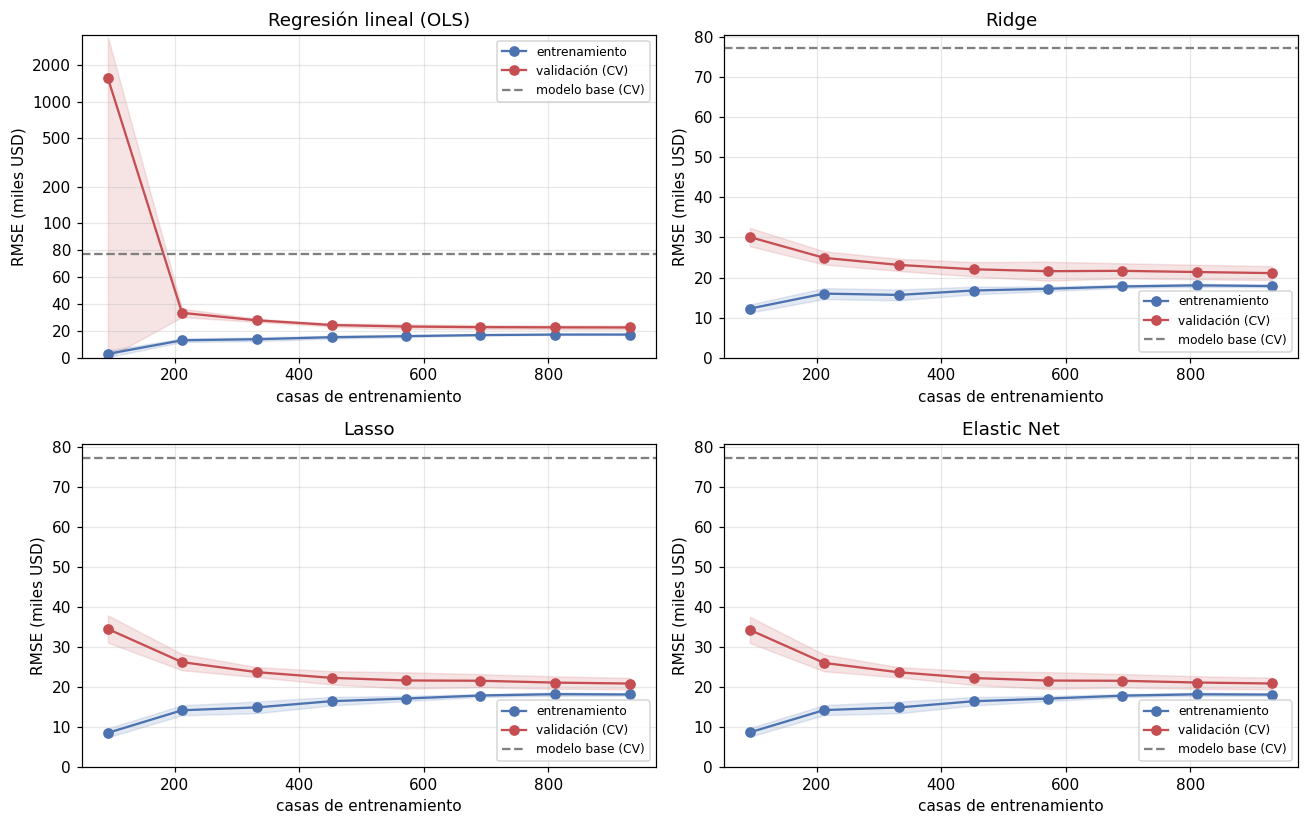

In [21]:
plot_learning_curves(list(linear_specs))

La regresión lineal sin regularización tiene un RMSE de validación de 22,445 dólares. Con Ridge baja a 21,113, con Lasso a 20,928 y con Elastic Net a 20,938. Lasso y Elastic Net quedan prácticamente empatados.

La regularización ayuda a que el modelo no se ajuste tanto a detalles del entrenamiento. En Lasso el error de entrenamiento es de 18,379 dólares, comparado con 20,928 en validación. Todavía hay una diferencia, pero es menor que en varios de los otros modelos. Las curvas permiten revisar qué pasa cuando hay pocas casas; no podemos asegurar solamente con esto que conseguir más datos ya no ayudaría.

### 8b. Árbol de decisión

In [22]:
tree_grid = {"reg__regressor__max_depth": [3, 4, 5, 6, 8, 10, 12, None],
             "reg__regressor__min_samples_leaf": [1, 2, 5, 10, 20],
             "reg__regressor__max_features": [None, 0.5]}
evaluate("Árbol de decisión", make_model(DecisionTreeRegressor(random_state=RANDOM_STATE), "tree"), tree_grid)

Árbol de decisión · mejores hiperparámetros: {'max_depth': 8, 'max_features': None, 'min_samples_leaf': 10}


,CV RMSE,CV RMSE desv.,CV MAE,CV R2,CV MAPE (%),Train RMSE,Test RMSE,Test MAE,Test R2,Test MAPE (%),Tiempo ajuste (s),Tiempo búsqueda (s)
Árbol de decisión,"32,171","2,274","21,973",0.8255,13.09,"22,682","31,626","22,547",0.8177,13.57,0.22,74.86


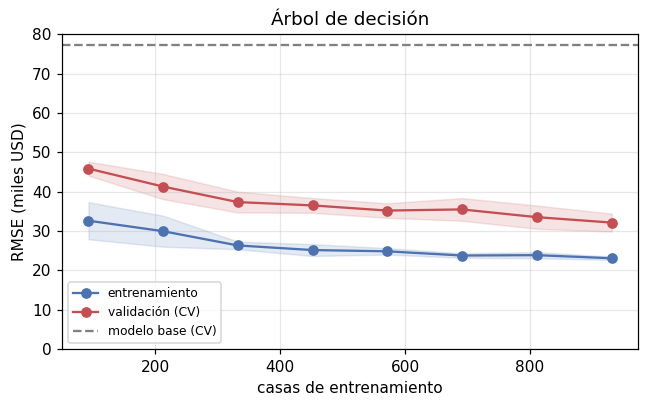

In [23]:
plot_learning_curves(["Árbol de decisión"], ncols=1)

El árbol elegido tiene profundidad máxima de 8 y al menos 10 casas por hoja. Su RMSE de validación es de 32,171 dólares, frente a 22,682 en entrenamiento. Mejora al modelo base, pero es el que más se equivoca de los modelos comparados.

Limitar la profundidad y pedir varias casas por hoja evita que se hagan grupos demasiado pequeños. Aun así, queda una diferencia importante entre entrenamiento y validación. El árbol es fácil de entender, pero con esta configuración no logra predecir tan bien como los otros modelos.

### 8c. Bosque aleatorio

In [24]:
rf_grid = {"reg__regressor__n_estimators": [300, 500, 800],
           "reg__regressor__max_features": [0.1, 0.2, 0.33, 0.5, "sqrt"],
           "reg__regressor__min_samples_leaf": [1, 2, 3, 5],
           "reg__regressor__max_depth": [None, 10, 20, 30],
           "reg__regressor__max_samples": [None, 0.7, 0.9]}
rf = RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1)
evaluate("Bosque aleatorio", make_model(rf, "tree"), rf_grid, n_iter=30)

Bosque aleatorio · mejores hiperparámetros: {'n_estimators': 500, 'min_samples_leaf': 2, 'max_samples': None, 'max_features': 0.5, 'max_depth': 10}


,CV RMSE,CV RMSE desv.,CV MAE,CV R2,CV MAPE (%),Train RMSE,Test RMSE,Test MAE,Test R2,Test MAPE (%),Tiempo ajuste (s),Tiempo búsqueda (s)
Bosque aleatorio,"25,583","1,729","16,215",0.8890,9.39,"12,354","23,366","15,390",0.9005,9.23,17.47,622.41


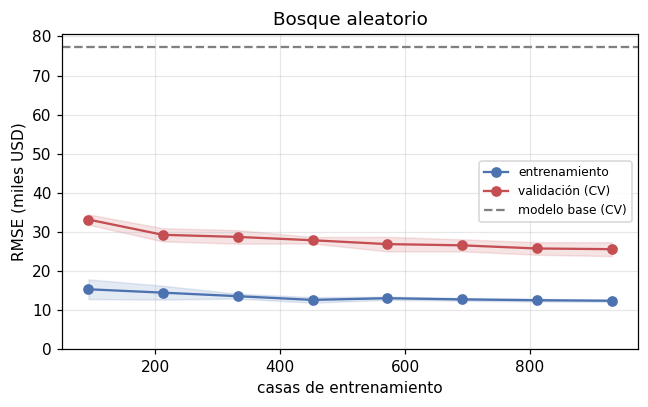

In [25]:
plot_learning_curves(["Bosque aleatorio"], ncols=1)

El bosque elegido usa 500 árboles, profundidad máxima de 10, aproximadamente la mitad de las variables disponibles en cada división y al menos 2 casas por hoja. Su RMSE de validación es de 25,583 dólares, mejor que el árbol individual.

En entrenamiento el RMSE baja hasta 12,354 dólares. Esa diferencia con validación indica sobreajuste: le va mucho mejor con las casas que ya usó para aprender. Combinar varios árboles ayuda, pero no garantiza quitar ese problema. Por eso no lo elegimos solamente por su error de entrenamiento.

### 8d. XGBoost

In [26]:
xgb_grid = {"reg__regressor__n_estimators": [400, 800, 1200, 2000],
            "reg__regressor__learning_rate": [0.01, 0.02, 0.05, 0.1],
            "reg__regressor__max_depth": [2, 3, 4, 5, 6],
            "reg__regressor__min_child_weight": [1, 2, 4, 8],
            "reg__regressor__subsample": [0.5, 0.7, 0.85, 1.0],
            "reg__regressor__colsample_bytree": [0.1, 0.2, 0.3, 0.5, 0.7, 1.0],
            "reg__regressor__reg_lambda": [0.01, 0.1, 1, 5, 10],
            "reg__regressor__reg_alpha": [0, 0.001, 0.01, 0.1]}
xgb = XGBRegressor(tree_method="hist", random_state=RANDOM_STATE, n_jobs=1)
evaluate("XGBoost", make_model(xgb, "tree"), xgb_grid, n_iter=50)

XGBoost · mejores hiperparámetros: {'subsample': 0.7, 'reg_lambda': 0.1, 'reg_alpha': 0.01, 'n_estimators': 800, 'min_child_weight': 2, 'max_depth': 3, 'learning_rate': 0.05, 'colsample_bytree': 0.3}


,CV RMSE,CV RMSE desv.,CV MAE,CV R2,CV MAPE (%),Train RMSE,Test RMSE,Test MAE,Test R2,Test MAPE (%),Tiempo ajuste (s),Tiempo búsqueda (s)
XGBoost,"21,718","1,689","13,977",0.9201,8.16,"7,609","20,257","13,981",0.9252,8.11,3.83,941.58


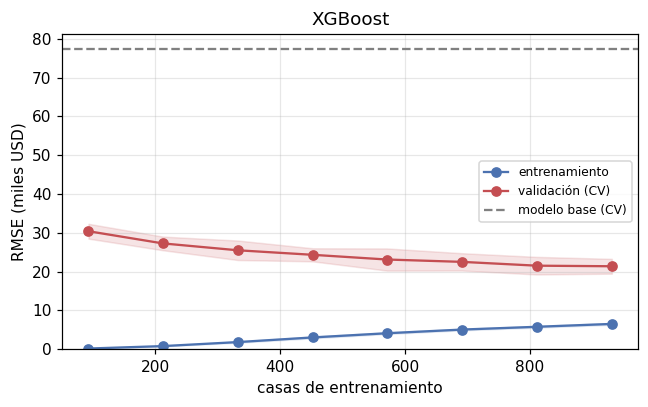

In [27]:
plot_learning_curves(["XGBoost"], ncols=1)

XGBoost obtiene un RMSE de validación de 21,718 dólares y de entrenamiento de 7,609. La configuración elegida usa 800 árboles, profundidad de 3 y tasa de aprendizaje de 0.05. Usa el 70% de las filas y el 30% de las columnas en cada árbol.

Mejora al bosque aleatorio, pero sigue teniendo una diferencia considerable entre entrenamiento y validación (casi 3 veces). Su curva de validación sigue bajando al final, así que es el modelo que más podría ganar con más datos. En prueba tiene un RMSE de 20,257 dólares; ese resultado se reporta sin usarlo para volver a ajustar la configuración.

### 8e. Red neuronal de perceptrón multicapa (MLP)

In [28]:
mlp_grid = {"reg__regressor__hidden_layer_sizes": [(32,), (64,), (128,), (64, 32), (128, 64), (256, 128)],
            "reg__regressor__alpha": [0.001, 0.01, 0.1, 1, 3, 10, 30],
            "reg__regressor__learning_rate_init": [0.0001, 0.0003, 0.001, 0.003],
            "reg__regressor__batch_size": [32, 64]}
mlp = MLPRegressor(max_iter=3000, early_stopping=True, validation_fraction=0.1, n_iter_no_change=30,
                   random_state=RANDOM_STATE)
evaluate("Red neuronal MLP", make_model(mlp, "linear"), mlp_grid, n_iter=30)

Red neuronal MLP · mejores hiperparámetros: {'learning_rate_init': 0.001, 'hidden_layer_sizes': (64, 32), 'batch_size': 32, 'alpha': 0.1}


,CV RMSE,CV RMSE desv.,CV MAE,CV R2,CV MAPE (%),Train RMSE,Test RMSE,Test MAE,Test R2,Test MAPE (%),Tiempo ajuste (s),Tiempo búsqueda (s)
Red neuronal MLP,"21,717","1,944","14,521",0.9197,8.70,"11,345","23,302","16,071",0.9010,9.06,3.18,461.85


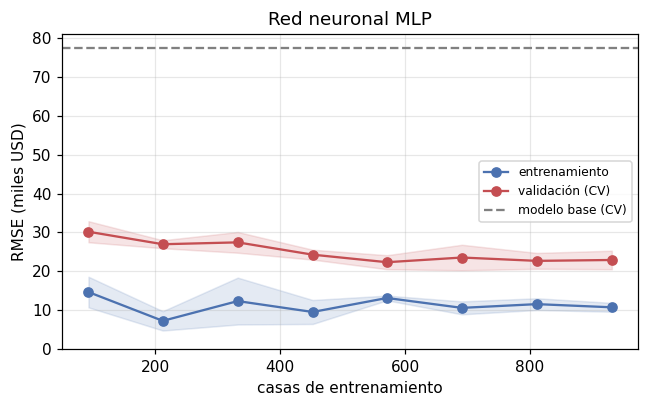

In [29]:
plot_learning_curves(["Red neuronal MLP"], ncols=1)

La red elegida tiene dos capas ocultas, de 64 y 32 neuronas, y regularización de 0.1. Su RMSE de validación es de 21,717 dólares, cercano al de XGBoost. En entrenamiento obtiene 11,345, así que también hay señales de sobreajuste. En prueba el error sube a 23,302.

Una red más compleja no necesariamente predice mejor. En estos resultados no supera a Lasso ni a SVR. La parada temprana ayuda a controlar el entrenamiento, pero no garantiza que no exista sobreajuste. Al ejecutarla, no aparecieron avisos de convergencia.

### 8f. Máquina de vector soporte (SVR)

In [30]:
svr_grid = {"reg__regressor__C": [1, 3, 10, 30, 100, 300, 1000],
            "reg__regressor__gamma": ["scale", 0.0001, 0.0003, 0.001, 0.003],
            "reg__regressor__epsilon": [0.005, 0.02, 0.05, 0.1]}
evaluate("SVR (kernel RBF)", make_model(SVR(kernel="rbf"), "linear"), svr_grid)

SVR (kernel RBF) · mejores hiperparámetros: {'C': 100, 'epsilon': 0.05, 'gamma': 0.0003}


,CV RMSE,CV RMSE desv.,CV MAE,CV R2,CV MAPE (%),Train RMSE,Test RMSE,Test MAE,Test R2,Test MAPE (%),Tiempo ajuste (s),Tiempo búsqueda (s)
SVR (kernel RBF),"19,475","1,845","12,334",0.9354,7.48,"15,575","19,476","13,350",0.9309,7.91,0.85,424.59


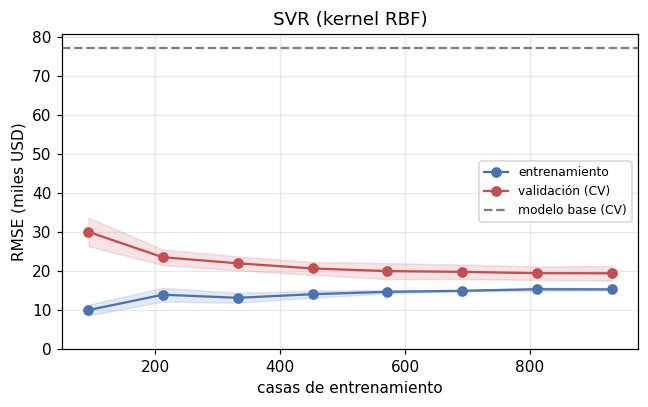

In [31]:
plot_learning_curves(["SVR (kernel RBF)"], ncols=1)

SVR con kernel RBF obtiene el menor RMSE de validación: aproximadamente 19,475 dólares. Su MAE es de 12,334, su R² de 0.9354 y su MAPE de 7.48%. La configuración elegida es C = 100, gamma = 0.0003 y epsilon = 0.05.

En entrenamiento su RMSE es de 15,575 dólares. Hay una diferencia, pero es menor que la del bosque, XGBoost y la red neuronal. Por eso la consideramos la mejor opción individual entre las que probamos: tiene el menor error de validación sin depender solamente de que le vaya bien en entrenamiento. En prueba obtiene un RMSE de 19,476 dólares, parecido al de validación. Esto no garantiza que funcione igual en cualquier ciudad o con datos futuros.

### 8g. Resumen comparativo

In [32]:
summary = pd.DataFrame(RESULTS).T.sort_values("CV RMSE")
parameter_labels = []
for name in summary.index:
    labels = []
    for parameter, value in PARAMS[name].items():
        labels.append(f"{parameter}={value}")
    parameter_labels.append(", ".join(labels) or "—")
summary.insert(0, "Hiperparámetros", parameter_labels)
fmt(summary)

,Hiperparámetros,CV RMSE,CV RMSE desv.,CV MAE,CV R2,CV MAPE (%),Train RMSE,Test RMSE,Test MAE,Test R2,Test MAPE (%),Tiempo ajuste (s),Tiempo búsqueda (s)
SVR (kernel RBF),"C=100, epsilon=0.05, gamma=0.0003","19,475","1,845","12,334",0.9354,7.48,"15,575","19,476","13,350",0.9309,7.91,0.85,424.59
Lasso,alpha=0.001,"20,928","1,411","13,644",0.9255,8.08,"18,379","21,260","13,922",0.9176,7.72,4.26,197.43
Elastic Net,"alpha=0.001778, l1_ratio=0.5","20,938","1,450","13,658",0.9254,8.09,"18,373","21,277","13,912",0.9175,7.72,2.66,428.85
Ridge,alpha=6.813,"21,113","1,727","13,759",0.9241,8.16,"18,053","21,290","13,872",0.9174,7.70,1.75,137.19
Red neuronal MLP,"learning_rate_init=0.001, hidden_layer_sizes=(64, 32), batch_size=32, alpha=0.1","21,717","1,944","14,521",0.9197,8.70,"11,345","23,302","16,071",0.9010,9.06,3.18,461.85
XGBoost,"subsample=0.7, reg_lambda=0.1, reg_alpha=0.01, n_estimators=800, min_child_weight=2, max_depth=3, learning_rate=0.05, colsample_bytree=0.3","21,718","1,689","13,977",0.9201,8.16,"7,609","20,257","13,981",0.9252,8.11,3.83,941.58
Regresión lineal (OLS),—,"22,445","1,395","14,628",0.9148,8.75,"17,521","22,038","14,578",0.9115,8.08,2.31,32.96
Bosque aleatorio,"n_estimators=500, min_samples_leaf=2, max_samples=None, max_features=0.5, max_depth=10","25,583","1,729","16,215",0.8890,9.39,"12,354","23,366","15,390",0.9005,9.23,17.47,622.41
Árbol de decisión,"max_depth=8, max_features=None, min_samples_leaf=10","32,171","2,274","21,973",0.8255,13.09,"22,682","31,626","22,547",0.8177,13.57,0.22,74.86


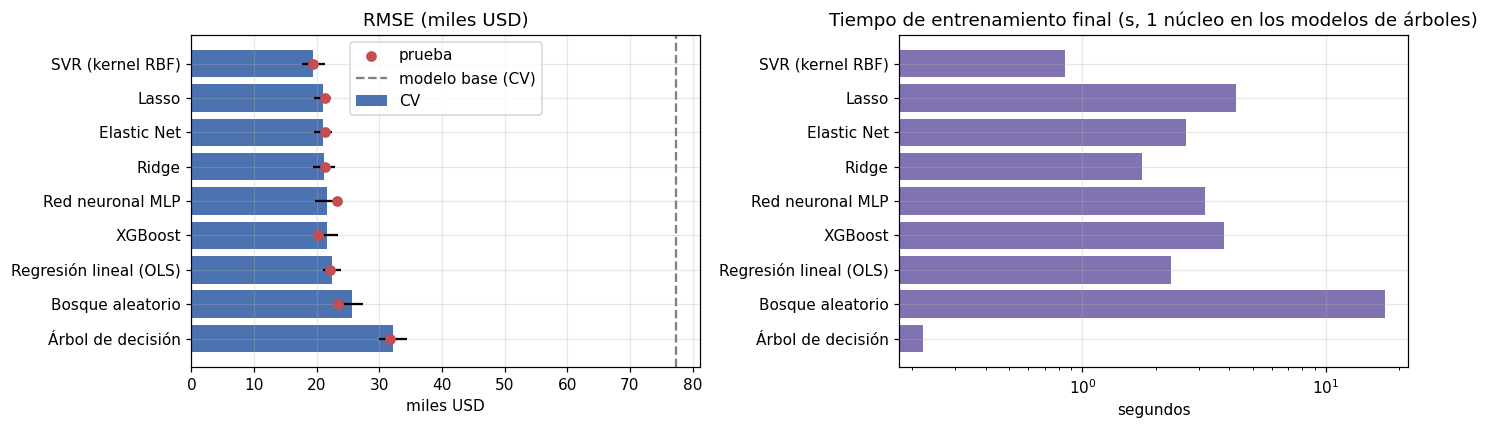

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
order = summary.index[::-1]
axes[0].barh(order, summary.loc[order, "CV RMSE"] / 1000, xerr=summary.loc[order, "CV RMSE desv."] / 1000,
             color="#4C72B0", label="CV")
axes[0].scatter(summary.loc[order, "Test RMSE"] / 1000, order, color="#C44E52", zorder=3, label="prueba")
axes[0].axvline(BASELINE_RMSE / 1000, ls="--", color="gray", label="modelo base (CV)")
axes[0].set(title="RMSE (miles USD)", xlabel="miles USD")
axes[0].legend()
axes[1].barh(order, summary.loc[order, "Tiempo ajuste (s)"], color="#8172B2")
axes[1].set(title="Tiempo de entrenamiento final (s, 1 núcleo en los modelos de árboles)", xscale="log", xlabel="segundos")
plt.tight_layout()
plt.show()

Todos los modelos mejoran al modelo base. Por RMSE de validación, el orden es: SVR, Lasso, Elastic Net, Ridge, MLP, XGBoost, regresión lineal sin regularización, bosque aleatorio y árbol de decisión.

Lasso y Elastic Net están muy cerca, al igual que MLP y XGBoost. No tomamos una diferencia pequeña como prueba de que uno siempre será mejor. SVR queda primero en esta comparación. El bosque, XGBoost y MLP tienen diferencias grandes entre entrenamiento y validación, por lo que todavía muestran sobreajuste.

La tabla también incluye el tiempo de ajuste y de búsqueda. Buscar configuraciones tarda mucho más que entrenar una sola vez. Que el resultado de prueba sea parecido al de validación es una buena señal, pero no demuestra que todo el proceso esté libre de sesgos.

## 9. Análisis de factores del mejor modelo (pregunta 10)

Primero revisamos qué columnas necesita más el mejor modelo. Después usamos unas gráficas para ver cómo cambian sus predicciones y dejamos Lasso como comparación. Estas explicaciones ayudan a entender los resultados, pero no prueban que una característica sea la causa del precio.


Mejor modelo por RMSE de validación cruzada: SVR (kernel RBF)


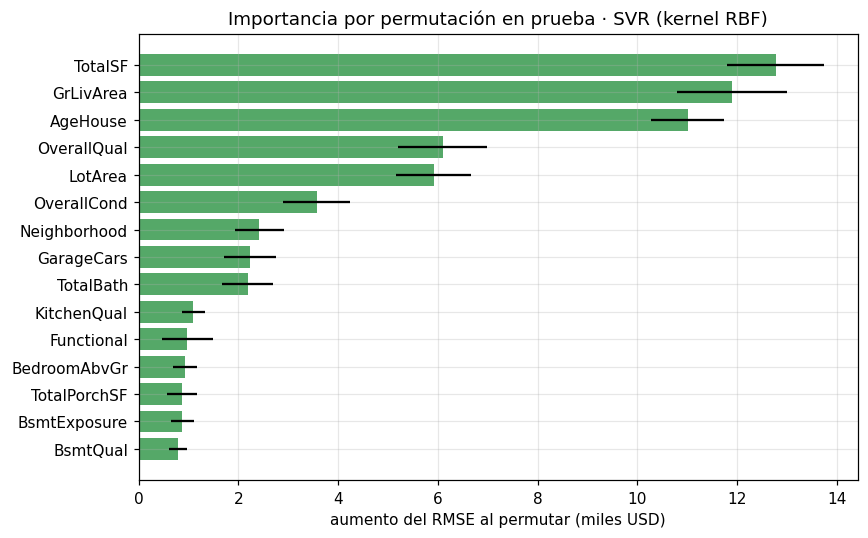

,aumento del RMSE (USD),desv.
TotalSF,12767.0,967.0
GrLivArea,11895.0,1105.0
AgeHouse,11004.0,739.0
OverallQual,6092.0,893.0
LotArea,5912.0,756.0
OverallCond,3567.0,666.0
Neighborhood,2420.0,495.0
GarageCars,2232.0,528.0
TotalBath,2184.0,507.0
KitchenQual,1098.0,232.0


In [34]:
best_name = summary.index[0]
best_model = BEST[best_name]
print(f"Mejor modelo por RMSE de validación cruzada: {best_name}")
perm = permutation_importance(best_model, X_test, y_test, scoring="neg_root_mean_squared_error",
                              n_repeats=15, random_state=RANDOM_STATE, n_jobs=-1)
importance = pd.DataFrame({"aumento del RMSE (USD)": perm.importances_mean, "desv.": perm.importances_std},
                          index=X_test.columns).sort_values("aumento del RMSE (USD)", ascending=False)
top = importance.head(15)[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top["aumento del RMSE (USD)"] / 1000, xerr=top["desv."] / 1000, color="#55A868")
ax.set(title=f"Importancia por permutación en prueba · {best_name}", xlabel="aumento del RMSE al permutar (miles USD)")
plt.tight_layout()
plt.show()
importance.head(15).round(0)

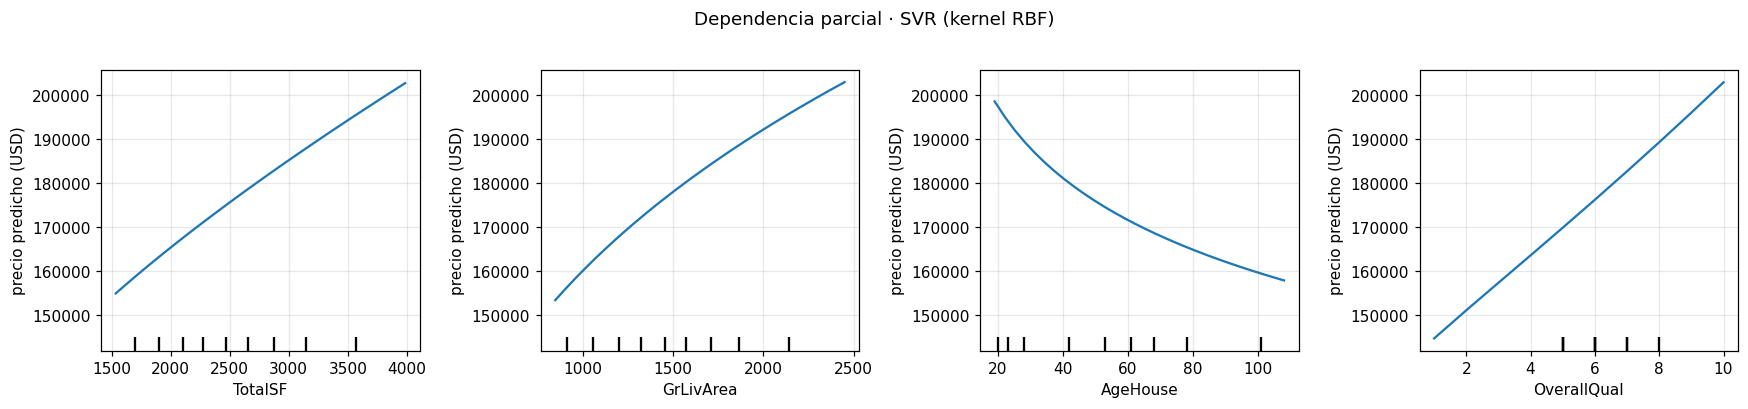

In [35]:
pd_features = []
for column in importance.index:
    if column in numeric_cols:
        pd_features.append(column)
    if len(pd_features) == 4:
        break
fig, axes = plt.subplots(1, len(pd_features), figsize=(4 * len(pd_features), 3.6))
PartialDependenceDisplay.from_estimator(best_model, X_train, pd_features, kind="average", ax=axes,
                                        grid_resolution=30)
for ax in np.ravel(axes):
    ax.set_ylabel("precio predicho (USD)")
plt.suptitle(f"Dependencia parcial · {best_name}", y=1.02)
plt.tight_layout()
plt.show()

In [36]:
def category_effect(feature, min_count=15):
    counts = X_train[feature].value_counts()
    rows = {}
    for level in counts[counts >= min_count].index:
        Xc = X_test.copy()
        Xc[feature] = level
        rows[level] = best_model.predict(Xc).mean()
    return pd.Series(rows).sort_values()


nominal_top = [c for c in importance.index if c in nominal_cols][:1]
ordinal_top = [c for c in importance.index if c in ordinal_cols][:1]
for feat in nominal_top + ordinal_top:
    eff = category_effect(feat) / 1000
    print(f"{feat} ({len(eff)} niveles con ≥ 15 casas) · precio promedio predicho, miles USD:")
    labels = []
    for level, value in eff.items():
        labels.append(f"{level} {value:,.0f}")
    print("   " + " < ".join(labels))

Neighborhood (19 niveles con ≥ 15 casas) · precio promedio predicho, miles USD:
   Edwards 168 < CollgCr 174 < Mitchel 175 < Timber 175 < SawyerW 175 < NAmes 175 < Gilbert 175 < NWAmes 176 < OldTown 176 < Sawyer 178 < SWISU 179 < IDOTRR 182 < ClearCr 185 < NridgHt 186 < NoRidge 187 < Somerst 187 < BrkSide 190 < StoneBr 193 < Crawfor 199
KitchenQual (4 niveles con ≥ 15 casas) · precio promedio predicho, miles USD:
   Fa 176 < TA 178 < Gd 180 < Ex 184


In [37]:
lasso = BEST["Lasso"]
names = lasso.named_steps["prep"].get_feature_names_out()
coef = pd.Series(lasso.named_steps["reg"].regressor_.coef_, index=names)
scale = lasso.named_steps["reg"].transformer_.named_steps["standardscaler"].scale_[0]
effect = (np.exp(coef * scale) - 1) * 100
print(f"Lasso conserva {int((coef != 0).sum())} de {len(coef)} columnas")
top_coef = effect.reindex(effect.abs().sort_values(ascending=False).index).head(15).round(1)
top_coef.index = top_coef.index.str.replace("infrequent_sklearn", "(categorías infrecuentes)")
kind = []
for feature in top_coef.index:
    label = "+1 desviación estándar"
    for column in nominal_cols:
        if feature.startswith(column + "_"):
            label = "categoría (vs. referencia)"
            break
    kind.append(label)
pd.DataFrame({"% de cambio en precio": top_coef, "efecto de": kind})

Lasso conserva 94 de 172 columnas


,% de cambio en precio,efecto de
MSZoning_(categorías infrecuentes),-24.3,categoría (vs. referencia)
Neighborhood_Crawfor,14.2,categoría (vs. referencia)
Neighborhood_StoneBr,11.3,categoría (vs. referencia)
TotalSF,9.7,+1 desviación estándar
SaleType_New,9.7,categoría (vs. referencia)
Neighborhood_BrkSide,7.8,categoría (vs. referencia)
Exterior1st_BrkFace,7.2,categoría (vs. referencia)
Neighborhood_NridgHt,7.1,categoría (vs. referencia)
Neighborhood_NoRidge,6.4,categoría (vs. referencia)
OverallQual,6.4,+1 desviación estándar


### Pregunta 10. Factores del mejor modelo

Elegimos SVR por su RMSE de validación. Para ver qué información utiliza, revolvemos una columna a la vez y medimos cuánto aumenta el error. Si aumenta mucho, esa columna era importante para sus predicciones. Este análisis de prueba se hace después de elegir el modelo; no lo usamos para volver a seleccionar variables ni ajustar configuraciones.

Los cuatro factores con mayor importancia en la tabla son:

- **Superficie total (`TotalSF`):** el error aumenta unos 12,767 dólares al revolverla. Incluye el sótano y los pisos. Tiene sentido que el espacio disponible ayude a estimar el precio.
- **Superficie habitable sobre el suelo (`GrLivArea`):** el error aumenta unos 11,895 dólares. También representa tamaño, pero no mide exactamente lo mismo que la superficie total.
- **Edad de la casa (`AgeHouse`):** el error aumenta unos 11,004 dólares. Ayuda a distinguir casas de diferentes épocas. No significa que una casa vieja siempre valga menos, porque también influyen su estado y ubicación.
- **Calidad general (`OverallQual`):** el error aumenta unos 6,092 dólares. Dos casas del mismo tamaño pueden tener precios distintos por sus materiales y acabados.

La ubicación (`Neighborhood`) también aparece entre las variables importantes, aunque no está entre las primeras cuatro, y el tamaño del terreno (`LotArea`) queda prácticamente empatado con la calidad general. Para una inmobiliaria, estos resultados indican que conviene registrar bien el tamaño, la edad, la calidad y la ubicación antes de estimar un precio.

En las **gráficas de dependencia parcial**, el precio predicho sube con la superficie total casi en línea recta, y con la superficie habitable sube cada vez menos (rendimientos decrecientes). Con la edad baja más rápido en las primeras décadas y después se estabiliza, y con la calidad general crece de forma casi lineal (≈ 6,500 dólares por punto).

Que el error aumente 12,767 dólares no significa que esa característica agregue esa cantidad al precio. Es una medida de cuánto depende el modelo de esa información. Además, tamaño y otras variables están relacionadas, así que la importancia se puede repartir entre ellas. Las gráficas muestran asociaciones del modelo, no prueban causas. Cambiar una sola característica dejando todas las demás fijas puede representar una casa poco realista.

Los coeficientes de Lasso quedan como comparación adicional, pero explican Lasso, no SVR. En las variables numéricas transformadas, un cambio de una desviación estándar se refiere a la escala transformada, no directamente a pies cuadrados o años.

## 10. Selección de los tres mejores modelos con RMSE + MAE (pregunta 11)

In [38]:
summary["CV RMSE+MAE"] = summary["CV RMSE"] + summary["CV MAE"]
summary["Test RMSE+MAE"] = summary["Test RMSE"] + summary["Test MAE"]
FAMILY = {"Regresión lineal (OLS)": "lineal", "Ridge": "lineal", "Lasso": "lineal", "Elastic Net": "lineal",
          "Árbol de decisión": "árbol", "Bosque aleatorio": "bosque", "XGBoost": "boosting",
          "Red neuronal MLP": "red neuronal", "SVR (kernel RBF)": "SVM"}
ranking = summary.sort_values("CV RMSE+MAE")[["CV RMSE", "CV MAE", "CV RMSE+MAE", "Test RMSE", "Test MAE", "Test RMSE+MAE"]]
ranking.insert(0, "familia", [FAMILY[n] for n in ranking.index])
top3 = ranking.drop_duplicates("familia").index[:3].tolist()
print("Tres mejores modelos (uno por familia, ordenados por CV RMSE+MAE):", top3)
fmt(ranking)

Tres mejores modelos (uno por familia, ordenados por CV RMSE+MAE): ['SVR (kernel RBF)', 'Lasso', 'XGBoost']


,familia,CV RMSE,CV MAE,CV RMSE+MAE,Test RMSE,Test MAE,Test RMSE+MAE
SVR (kernel RBF),SVM,"19,475","12,334","31,808","19,476","13,350","32,827"
Lasso,lineal,"20,928","13,644","34,572","21,260","13,922","35,181"
Elastic Net,lineal,"20,938","13,658","34,596","21,277","13,912","35,189"
Ridge,lineal,"21,113","13,759","34,871","21,290","13,872","35,162"
XGBoost,boosting,"21,718","13,977","35,695","20,257","13,981","34,238"
Red neuronal MLP,red neuronal,"21,717","14,521","36,238","23,302","16,071","39,373"
Regresión lineal (OLS),lineal,"22,445","14,628","37,072","22,038","14,578","36,616"
Bosque aleatorio,bosque,"25,583","16,215","41,798","23,366","15,390","38,756"
Árbol de decisión,árbol,"32,171","21,973","54,144","31,626","22,547","54,173"


### Pregunta 11. Los tres mejores modelos según RMSE + MAE

La suma de RMSE + MAE en validación cruzada **selecciona SVR (31,808 USD), Lasso (34,572 USD) y XGBoost (35,695 USD)**. La red neuronal queda cerca, en cuarto lugar (36,238 USD).

Tomamos **un modelo por familia**. Elastic Net y Ridge tienen casi la misma suma que Lasso, pero son variantes del mismo modelo lineal con el mismo preprocesamiento y producen predicciones casi idénticas. Elegir tres variantes lineales haría inútil el ensamble de las preguntas 13 y 14, que necesita modelos con errores distintos. Para la selección usamos la validación cruzada y no la prueba, para no elegir con datos que deben quedar intactos.

**¿Qué ventajas tiene usar la suma RMSE + MAE?**

* **Las dos métricas están en dólares**, así que la suma se interpreta directamente como dinero.
* **Mide dos riesgos de negocio a la vez.** El MAE es el error típico por casa: lo que en promedio se desvía una valuación, que es lo que siente un cliente o un agente en una negociación. El RMSE eleva al cuadrado los errores y castiga los **errores grandes**: valuar mal por 100,000 USD una casa cara puede costar una venta, una comisión o la reputación de la inmobiliaria.
* **Detecta modelos con errores extremos.** Como el RMSE siempre es mayor o igual que el MAE, y la diferencia entre ambos crece cuando hay errores grandes, la suma favorece a los modelos que son precisos en general **y** que no tienen errores catastróficos.
* **Es más estable que cada métrica por separado** al comparar modelos con desempeño parecido.

**Desventajas:**

* El peso 1:1 es arbitrario. Si a la empresa le preocupan más los errores grandes, convendría ponderar más el RMSE.
* Las dos métricas están muy correlacionadas, así que la suma cuenta dos veces gran parte de la misma información.
* Ambas son absolutas y están dominadas por las casas caras: un error de 15,000 USD pesa igual en una casa de 80,000 que en una de 500,000. El MAPE refleja mejor el error relativo de las casas económicas.
* No es una métrica estándar, lo que dificulta compararla con otros trabajos. Además, los algoritmos no la optimizan directamente: ajustamos los hiperparámetros con RMSE.

En nuestros resultados, la suma sí decide el tercer lugar: por RMSE solo, la red neuronal y XGBoost quedan empatados (1 USD de diferencia), y el MAE, claramente menor en XGBoost (13,977 contra 14,521 USD), inclina la selección hacia él. Es justamente el caso en que combinar las dos métricas aporta información.

## 11. Métodos de ensamble: votación y apilamiento (preguntas 12, 13 y 14)

### Pregunta 12. ¿En qué consisten `VotingRegressor` y `StackingRegressor`?

Los dos son métodos de **aprendizaje en conjunto** (*ensemble learning*): combinan las predicciones de varios modelos ya construidos para obtener una predicción más estable que la de cada uno por separado. Funcionan mejor cuando los modelos cometen **errores distintos** (poco correlacionados): al combinarlos, parte del error se cancela.

* **`VotingRegressor` (votación o promedio).** Entrena cada modelo base de forma independiente con los mismos datos y predice el **promedio**, simple o ponderado con `weights`, de sus predicciones. No aprende nada adicional: es barato, fácil de explicar y reduce la varianza. Su limitación es que un modelo débil pesa lo mismo que uno fuerte, salvo que se fijen pesos a mano.
* **`StackingRegressor` (apilamiento).** Agrega un segundo nivel de aprendizaje. Con validación cruzada interna (`cv`) obtiene predicciones **fuera de muestra** (*out-of-fold*) de cada modelo base y las usa como variables de entrada de un **meta-modelo** (`final_estimator`), que aprende cuánto confiar en cada modelo base. Después reentrena los modelos base con todos los datos. Usar predicciones fuera de muestra es lo que evita que el meta-modelo premie al modelo base que más memorizó. Es más flexible que la votación, pero más costoso de entrenar y de mantener, y puede sobreajustarse si hay pocos datos.

En los dos casos, cada modelo base es **el pipeline completo** (preprocesamiento + transformación logarítmica + modelo), así que el ensamble recibe los datos crudos y no hay fuga de información.

In [39]:
def evaluate_ensemble(name, model):
    t0 = time.perf_counter()
    res = cross_validate(model, X_train, y_train, cv=CV, scoring=SCORING, n_jobs=-1)
    t_cv = time.perf_counter() - t0
    cv = cv_summary(res)
    t0 = time.perf_counter()
    model.fit(X_train, y_train)
    t_fit = time.perf_counter() - t0
    train = metrics(y_train, model.predict(X_train))
    test = metrics(y_test, model.predict(X_test))
    RESULTS[name] = {
        "CV RMSE": cv["rmse"].mean(), "CV RMSE desv.": cv["rmse"].std(), "CV MAE": cv["mae"].mean(),
        "CV R2": cv["r2"].mean(), "CV MAPE (%)": cv["mape"].mean(), "Train RMSE": train["RMSE"],
        "Test RMSE": test["RMSE"], "Test MAE": test["MAE"], "Test R2": test["R2"], "Test MAPE (%)": test["MAPE (%)"],
        "Tiempo ajuste (s)": t_fit, "Tiempo búsqueda (s)": t_cv,
    }
    BEST[name] = model
    return fmt(pd.DataFrame(RESULTS[name], index=[name]))


base_estimators = [(FAMILY[n].replace(" ", "_"), clone(BEST[n])) for n in top3]
voting = VotingRegressor(estimators=base_estimators)
evaluate_ensemble("VotingRegressor (top 3)", voting)

,CV RMSE,CV RMSE desv.,CV MAE,CV R2,CV MAPE (%),Train RMSE,Test RMSE,Test MAE,Test R2,Test MAPE (%),Tiempo ajuste (s),Tiempo búsqueda (s)
VotingRegressor (top 3),"19,679","1,659","12,543",0.9341,7.47,"13,062","19,339","12,935",0.9318,7.47,3.77,7.02


### Pregunta 13. `VotingRegressor` con los tres mejores modelos

La votación promedia, con el mismo peso, las predicciones en dólares de los pipelines completos de SVR, Lasso y XGBoost.

* En **validación cruzada** obtiene un RMSE de 19,679 USD: **204 USD peor que la SVR sola**. El promedio con pesos iguales le da dos tercios del peso a dos modelos más débiles.
* En **prueba** obtiene un RMSE de 19,339 USD y el **mejor MAE y MAPE de todos** (12,935 USD y 7.47%): promediar suaviza los errores grandes de cada modelo.
* Entrenarlo cuesta ≈ 3.8 s.

In [40]:
stacking = StackingRegressor(estimators=[(k, clone(m)) for k, m in base_estimators],
                             final_estimator=LinearRegression(positive=True), cv=CV, n_jobs=1)
display(evaluate_ensemble("StackingRegressor (top 3)", stacking))
meta = BEST["StackingRegressor (top 3)"].final_estimator_
weights = pd.Series(meta.coef_, index=[k for k, _ in base_estimators])
print("Pesos del meta-modelo (regresión lineal con coeficientes no negativos):", weights.round(3).to_dict(),
      f"| intercepto = {meta.intercept_:,.0f} USD | suma de pesos = {weights.sum():.3f}")

,CV RMSE,CV RMSE desv.,CV MAE,CV R2,CV MAPE (%),Train RMSE,Test RMSE,Test MAE,Test R2,Test MAPE (%),Tiempo ajuste (s),Tiempo búsqueda (s)
StackingRegressor (top 3),"19,401","1,845","12,496",0.9358,7.53,"13,373","19,071","13,308",0.9337,7.76,21.85,48.48


Pesos del meta-modelo (regresión lineal con coeficientes no negativos): {'SVM': 0.767, 'lineal': 0.047, 'boosting': 0.216} | intercepto = -4,686 USD | suma de pesos = 1.030


### Pregunta 14. `StackingRegressor` con los tres mejores modelos

El apilamiento usa como meta-modelo una **regresión lineal con coeficientes no negativos**, entrenada con predicciones *out-of-fold* de 5 folds. Elegimos coeficientes no negativos para que los pesos se interpreten como contribuciones.

* **El meta-modelo aprende pesos de 0.77 para SVR, 0.22 para XGBoost y 0.05 para Lasso** (suman ≈ 1.03, con un intercepto de −4,686 USD). En la práctica es un **promedio ponderado dominado por la SVR**. Lasso casi no aporta porque sus errores están muy correlacionados con los de la SVR (comparten el mismo preprocesamiento). XGBoost sí aporta algo porque se equivoca de manera distinta.
* Su RMSE de validación cruzada (19,401 USD) **queda 74 USD por debajo de la SVR sola** (19,475), una diferencia muy pequeña frente a la desviación entre folds (≈ 1,850 USD). En prueba mejora a 19,071 USD.
* Entrenarlo cuesta ≈ 21.9 s, unas **26 veces más que la SVR**, porque cada modelo base se entrena 6 veces.

## 12. Comparación de los ensambles con los tres mejores modelos (pregunta 15)

In [41]:
compare = pd.DataFrame(RESULTS).T.loc[top3 + ["VotingRegressor (top 3)", "StackingRegressor (top 3)"]]
compare["CV RMSE+MAE"] = compare["CV RMSE"] + compare["CV MAE"]
cols = ["CV RMSE", "CV RMSE desv.", "CV MAE", "CV RMSE+MAE", "Test RMSE", "Test MAE", "Test R2", "Test MAPE (%)",
        "Tiempo ajuste (s)"]
fmt(compare[cols].sort_values("CV RMSE"))

,CV RMSE,CV RMSE desv.,CV MAE,CV RMSE+MAE,Test RMSE,Test MAE,Test R2,Test MAPE (%),Tiempo ajuste (s)
StackingRegressor (top 3),"19,401","1,845","12,496","31,897","19,071","13,308",0.9337,7.76,21.85
SVR (kernel RBF),"19,475","1,845","12,334","31,808","19,476","13,350",0.9309,7.91,0.85
VotingRegressor (top 3),"19,679","1,659","12,543","32,223","19,339","12,935",0.9318,7.47,3.77
Lasso,"20,928","1,411","13,644","34,572","21,260","13,922",0.9176,7.72,4.26
XGBoost,"21,718","1,689","13,977","35,695","20,257","13,981",0.9252,8.11,3.83


In [42]:
rkf_final = RepeatedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE + 1)
paired = {}
for name in [top3[0], "VotingRegressor (top 3)", "StackingRegressor (top 3)"]:
    paired[name] = -cross_validate(clone(BEST[name]), X_train, y_train, cv=rkf_final,
                                   scoring="neg_root_mean_squared_error", n_jobs=-1)["test_score"]
paired = pd.DataFrame(paired)
diff = paired.drop(columns=top3[0]).sub(paired[top3[0]], axis=0)
paired_table = pd.DataFrame({
    "RMSE medio (15 folds)": paired.mean(),
    f"diferencia vs. {top3[0]}": [0.0] + diff.mean().tolist(),
    "folds en que gana al mejor individual": ["—"] + [f"{int((diff[c] < 0).sum())} de {len(diff)}" for c in diff],
})
paired_table.round(0)

,RMSE medio (15 folds),diferencia vs. SVR (kernel RBF),folds en que gana al mejor individual
SVR (kernel RBF),19440.0,0.0,—
VotingRegressor (top 3),19791.0,351.0,5 de 15
StackingRegressor (top 3),19498.0,58.0,7 de 15


### Pregunta 15. ¿Conviene usar un ensamble en lugar de un modelo individual?

En el conjunto de prueba, los dos ensambles parecen mejores que la SVR: el apilamiento baja el RMSE a 19,071 USD (-2.1%) y la votación a 19,339 USD (-0.7%). Pero la prueba tiene solo 292 casas, y la desviación entre folds es de ≈ 1,850 USD. Para saber si la ventaja es real, repetimos la validación cruzada **pareada** (los mismos 15 folds para los tres modelos):

| Modelo | Diferencia de RMSE frente a la SVR | Folds en los que gana a la SVR |
|---|---|---|
| Apilamiento | +58 USD | 7 de 15 |
| Votación | +351 USD | 5 de 15 |

**Ninguno de los dos supera a la SVR de forma consistente:** el apilamiento empata y la votación es ligeramente peor. La ventaja que se ve en prueba es variación del muestreo.

**Conclusión: por ahora no conviene sustituir la SVR por un ensamble.** Ofrecen la misma precisión con más costo: tres modelos que entrenar, versionar y monitorear, de 4 a 26 veces más tiempo de entrenamiento y una explicación más complicada para el negocio.

El apilamiento sí aporta una lección útil: **la SVR ya concentra casi toda la información**, y el único modelo que agrega algo es XGBoost, por equivocarse de forma distinta. Si en el futuro hay más datos y XGBoost mejora (su curva de aprendizaje sigue bajando), un ensamble SVR + XGBoost sería el primer candidato a reevaluar. La votación podría justificarse solo si la prioridad fuera el error típico (MAE) por encima de los errores grandes, porque en prueba tuvo el menor MAE y MAPE.

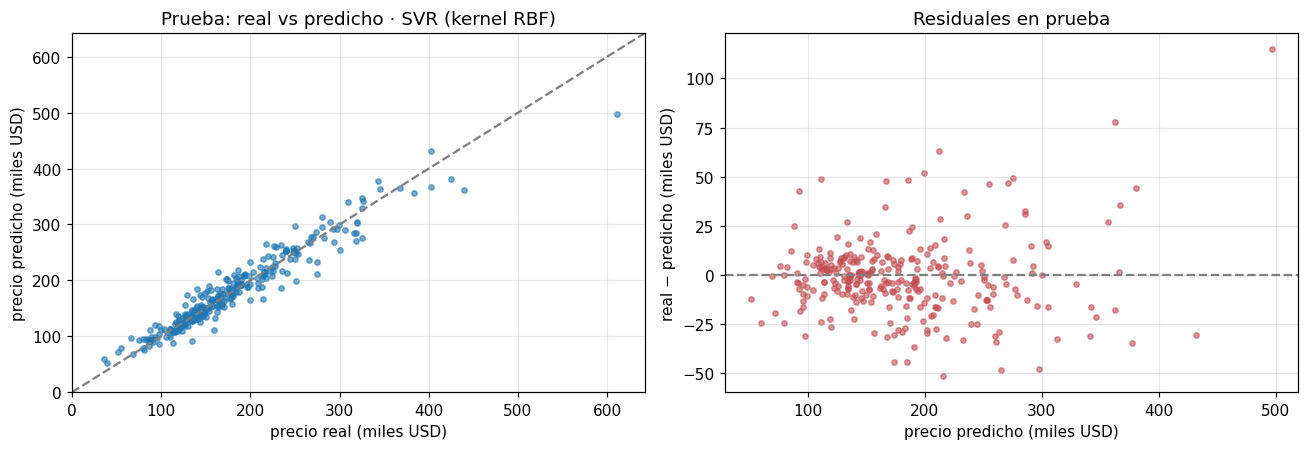

Error absoluto mediano: 8,421 USD | casas con error ≤ 10 %: 74.0% | con error > 20 %: 8.6%


,casas,MAPE,mediana
rango,,,
Q1 (más baratas),75,10.5,5.9
Q2,72,7.1,4.7
Q3,73,6.7,5.1
Q4 (más caras),72,7.3,5.3


In [44]:
final_name = top3[0]  # modelo recomendado: el mejor individual (los ensambles no lo superan de forma consistente)
final_model = BEST[final_name]
pred = final_model.predict(X_test)
resid = y_test - pred
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].scatter(y_test / 1000, pred / 1000, s=12, alpha=0.6)
lims = [0, max(y_test.max(), pred.max()) / 1000 * 1.05]
axes[0].plot(lims, lims, "--", color="gray")
axes[0].set(title=f"Prueba: real vs predicho · {final_name}", xlabel="precio real (miles USD)",
            ylabel="precio predicho (miles USD)", xlim=lims, ylim=lims)
axes[1].scatter(pred / 1000, resid / 1000, s=12, alpha=0.6, color="#C44E52")
axes[1].axhline(0, color="gray", ls="--")
axes[1].set(title="Residuales en prueba", xlabel="precio predicho (miles USD)", ylabel="real − predicho (miles USD)")
plt.tight_layout()
plt.show()
abs_pct = (resid.abs() / y_test * 100)
print(f"Error absoluto mediano: {resid.abs().median():,.0f} USD | casas con error ≤ 10 %: {(abs_pct <= 10).mean():.1%} "
      f"| con error > 20 %: {(abs_pct > 20).mean():.1%}")
by_band = pd.DataFrame({"real": y_test, "error %": abs_pct}).assign(
    rango=lambda d: pd.qcut(d.real, 4, labels=["Q1 (más baratas)", "Q2", "Q3", "Q4 (más caras)"]))
by_band.groupby("rango", observed=True)["error %"].agg(casas="count", MAPE="mean", mediana="median").round(1)

**Diagnóstico del modelo elegido (SVR) en prueba.**

* El **error absoluto mediano es de 8,421 USD**.
* **3 de cada 4 casas** (74%) se valúan con un error de ±10% o menos, y solo el 8.6% tiene un error mayor a 20%.
* El error relativo es mayor en el **cuartil de casas más baratas** (MAPE de 10.5% contra ≈ 7% en el resto). En las casas baratas el mismo error en dólares pesa más en porcentaje, y además son más heterogéneas (antiguas, en peor estado o con ventas atípicas).
* En los residuales, el error en dólares crece con el precio, pero el error relativo se mantiene: es la consecuencia esperada de modelar el logaritmo.
* El mayor error es una casa de 611,000 USD, que el modelo subestima en ≈ 115,000 USD. Las casas de lujo escasean en el entrenamiento, así que conviene que una persona revise las valuaciones altas.

## 13. Reportes finales (pregunta 16)

### 16a. Reporte para el equipo técnico

**Decisión recomendada: poner en producción el pipeline con SVR (kernel RBF; C = 100, γ = 0.0003, ε = 0.05).**

| Criterio | Evidencia | Decisión |
|---|---|---|
| **Métricas** | La SVR es el mejor modelo en validación cruzada (RMSE de 19,475 ± 1,845 USD; MAE de 12,334; R² de 0.935; MAPE de 7.5%), y la prueba lo confirma (RMSE de 19,476; R² de 0.931). Supera en 7% al mejor lineal y en 10% a XGBoost. | SVR como modelo principal. |
| **Ensambles** | Votación y apilamiento no la superan en validación cruzada repetida y pareada (+351 y +58 USD). | No adoptarlos por ahora; reevaluar SVR + XGBoost cuando haya más datos. |
| **Ajuste del modelo** | Brecha entre entrenamiento y validación moderada (razón de 1.25); curvas que convergen; hiperparámetros dentro de la malla, no en sus bordes. | Configuración estable. Repetir la búsqueda en cada reentrenamiento. |
| **Modelo de respaldo** | Lasso: 7% menos preciso, pero interpretable (coeficientes en % del precio) y casi sin sobreajuste. | Usarlo para explicar valuaciones, detectar desvíos y como alternativa si la SVR falla. |
| **Costo computacional** | La SVR entrena en ≈ 1 s y la búsqueda completa de hiperparámetros tarda unos minutos; predice en milisegundos. El entrenamiento de la SVR crece entre n² y n³ con el número de casas. | Sin infraestructura especial. Con más de unas 50,000 casas, migrar a XGBoost, que escala linealmente. |
| **Robustez** | El pipeline trata los NA estructurales, agrupa categorías raras, acota los valores atípicos (recorte a ±6 σ y tope de 10 millones de USD) y rechaza el filtrado de información. | Mantener las salvaguardas. Validar el esquema de entrada (tipos y rangos) antes de predecir. |

**Mantenimiento de la solución:**

1. **Alcance:** el modelo solo es válido para casas de hasta 4,000 pies² y del tipo de mercado del entrenamiento. Las solicitudes fuera de ese alcance deben enviarse a un valuador humano.
2. **Deriva del mercado:** por diseño, el modelo no usa el año de venta, así que **no sigue la inflación ni el ciclo inmobiliario**. Hay que reentrenarlo cada trimestre con ventas recientes o ajustar el nivel de precios con un índice de mercado.
3. **Datos:** el conjunto proviene de Ames, Iowa (2006–2010). Antes de usarlo en otro mercado, hay que reentrenarlo con datos locales y repetir esta evaluación.
4. **Monitoreo:** medir el MAPE por segmento de precio (el cuartil barato es el más débil, con 10.5%) y por colonia, y alertar cuando las variables de entrada se salgan de los rangos del entrenamiento.
5. **Reproducibilidad:** versionar el pipeline completo (por ejemplo, con `joblib`), las semillas y las versiones de scikit-learn y XGBoost. El preprocesamiento vive dentro del pipeline, así que no hay pasos manuales que replicar.
6. **Mejoras posibles:** agregar intervalos de predicción (regresión por cuantiles o *conformal prediction*); corregir el sesgo de la transformación logarítmica (al regresar a dólares, la predicción se acerca a la mediana y no a la media); y sumar variables externas de ubicación (escuelas, distancia a servicios).

### 16b. Reporte para la dirección de la empresa inmobiliaria

**¿Qué construimos?** Una herramienta que **estima en menos de un segundo el precio de una casa** a partir de sus características: tamaño, antigüedad, calidad de construcción, colonia, garaje, etcétera. Probamos seis tipos de inteligencia artificial y elegimos el más preciso y estable.

**¿Qué tan precisa es?** La probamos con 292 casas que el sistema nunca había visto:

* En la casa típica, **se equivoca por unos 8,400 USD**.
* **3 de cada 4 casas** quedan a menos de 10% de su precio real de venta, y en promedio la desviación es de 8%.
* Como referencia, estimar «el precio promedio» para todas las casas se equivoca en promedio por más de 55,000 USD.

**Beneficios:**

* **Rapidez y escala:** valuaciones preliminares instantáneas para toda la cartera, para cotizar o para filtrar oportunidades.
* **Consistencia:** aplica siempre los mismos criterios, sin depender de quién haga la estimación.
* **Explicaciones claras:** el precio depende sobre todo del tamaño, la antigüedad, la calidad y la colonia. Por ejemplo, en Crawfor la misma casa vale ≈ 18% más que en Edwards. Esto ayuda a argumentar precios con clientes.
* **Mejor uso del talento:** los valuadores se concentran en los casos complejos.

**Riesgos y cómo mitigarlos:**

* **Errores grandes en algunos casos:** cerca de 1 de cada 11 casas tiene un error mayor a 20%, sobre todo las más baratas y las de lujo. → **La herramienta apoya pero no sustituye** la valuación profesional. Los casos atípicos los revisa una persona.
* **Datos de otro mercado y otra época:** el sistema aprendió con ventas de 2006–2010 en una ciudad de Estados Unidos. → Antes de usarlo hay que **reentrenarlo con ventas recientes de nuestro mercado** y actualizarlo cada trimestre.
* **No es para todas las propiedades:** no aplica a residencias de más de 4,000 pies² ni a propiedades muy distintas a las del histórico.
* **Responsabilidad:** la valuación final y su firma siguen siendo responsabilidad de un valuador certificado.

**Costos:**

* **Cómputo: mínimo.** Se entrena en segundos en una computadora personal y no requiere servidores especiales.
* **Lo que sí cuesta:** conseguir y limpiar datos de ventas locales, integrarlo con nuestros sistemas y dedicar a un analista para actualizarlo y supervisarlo periódicamente.

**Recomendación:** aprobar un **piloto de 3 meses** en el que la herramienta dé una estimación preliminar y los valuadores la comparen con su dictamen. Si en el piloto se mantiene un error típico menor a 10%, extender su uso como apoyo en todas las cotizaciones.

# **Conclusiones**

Incluyan los comentarios y conclusiones de esta actividad. En particular, respondan sobre los siguientes puntos:

* ¿En qué casos el uso de LLMs fue de mayor provecho?
* ¿En cuáles casos la intervención como expertos en combinación con los LLM fue importante para alcanzar con los objetivos propuestos?


### +++++++++++ Inicia sección de Conclusiones Finales ++++++++++++++++

#### Pregunta 17. Conclusiones de la actividad

1. **Las decisiones sobre los datos pesaron tanto como la elección del algoritmo.** Modelar el logaritmo del precio, tratar como «no existe» los NA estructurales (alberca, garaje, sótano), convertir los años en edades y definir el alcance (casas de hasta 4,000 pies²) hizo que modelos tan simples como Lasso quedaran a solo 7% del mejor. Sin esos pasos, ningún ajuste de hiperparámetros lo habría compensado.
2. **El mejor modelo fue la SVR con kernel RBF**: RMSE de 19,475 USD en validación cruzada y de 19,476 en prueba, R² de 0.93 y MAPE de ≈ 8%. Redujo el error del modelo base en 75%. Le siguieron los lineales regularizados, XGBoost y la red neuronal, muy parejos entre sí. El bosque aleatorio y el árbol individual quedaron al final, porque no extrapolan y predicen por escalones.
3. **Las restricciones temporales fueron correctas y no costaron precisión.** Eliminar `YrSold` y `MoSold` no empeoró el error (lo comprobamos para `MoSold` con validación cruzada repetida), y la edad de la casa resultó ser el tercer factor más importante.
4. **Los ensambles no superaron al mejor modelo individual.** En el conjunto de prueba parecían entre 0.7 y 2.1% mejores, pero la validación cruzada repetida y pareada mostró que esa ventaja era ruido. Una sola partición de prueba de 292 casas no basta para decidir entre modelos tan cercanos: hay que comparar con varias particiones y con la misma métrica.
5. **Las curvas de aprendizaje sirvieron para más que diagnosticar el sobreajuste.** Revelaron que Yeo-Johnson, ajustado con pocos datos, producía valores extremos en variables casi siempre en cero (λ = −23.6 en `PoolArea`), y lo corregimos con un recorte a ±6 desviaciones. También mostraron que OLS colapsa cuando hay menos casas que columnas y que XGBoost es el modelo que más ganaría con más datos.
6. **Lo que determina el precio** es el tamaño (superficie total y habitable), la antigüedad, la calidad de construcción y la colonia, seguidos del garaje y los baños. El modelo aprendió reglas que coinciden con la lógica del mercado: rendimientos decrecientes del tamaño, depreciación más rápida en las primeras décadas y primas de ubicación que no son iguales al precio promedio de cada colonia.
7. **Limitaciones:** datos de un solo mercado y de 2006–2010, pocas casas de lujo, y un error relativo mayor en las casas más baratas. Por eso recomendamos usarlo como apoyo a la valuación profesional, con reentrenamiento periódico y revisión humana de los casos atípicos.

#### Uso de LLMs

* **¿En qué casos el uso de LLMs fue de mayor provecho?**
  * Escribir rápido el código repetitivo: pipelines con `ColumnTransformer`, mallas de hiperparámetros, la función común de evaluación, las curvas de aprendizaje y el formato de las tablas.
  * Recordar detalles de las APIs (`TransformedTargetRegressor`, `OneHotEncoder` con `min_frequency`, `StackingRegressor`).
  * Redactar una primera versión de las justificaciones y de los dos reportes, que después ajustamos con los números reales del notebook.
  * Explicar conceptos como la trampa de las variables dummy o la diferencia entre votación y apilamiento.

* **¿En qué casos fue importante la intervención como expertos en combinación con el LLM?**
  * **Interpretar el problema:** aplicar la restricción de «tendencias cronológicas absolutas» también a `GarageYrBlt`, que el enunciado no menciona, y tratar `MoSold` como un atributo de la transacción y no de la casa.
  * **Leer el diccionario de datos** para distinguir los NA que significan «no existe» de los faltantes reales, y verificarlo con las variables numéricas asociadas.
  * **Detectar errores que el código no reporta.** Con pandas 3, `MSSubClass` se clasificaba como numérica sin dar ningún error, y la copia de OpenML encerraba entre comillas algunas categorías. Solo se descubrieron revisando las salidas.
  * **Leer las curvas de aprendizaje con criterio**, encontrar la causa de los picos (λ extremos de Yeo-Johnson) y decidir cómo corregirla.
  * **Desconfiar de una mejora aparente en prueba** y comprobarla con validación cruzada repetida antes de recomendar un ensamble.
  * **Traducir los resultados** a decisiones de negocio y riesgos para los reportes técnico y ejecutivo.

### +++++++++++ Termina sección de conclusiones finales ++++++++++++++

# **Anexo**

**Incluir a continuación los prompts que consideren hayan sido los más importantes, así como el nombre del modelo LLM utilizado.**

### +++++++++++ Inicia sección de prompts ++++++++++++++++

**Modelos LLM utilizados:** 
* Claude Opus 5.5 (Anthropic), mediante Claude Code.
* ChatGPT (OpenAI).

**Prompt principal.** Se compartieron con el modelo los cuatro materiales oficiales de la actividad: el PDF *Actividad_Prediccion_Precios_Vivienda.pdf* con las 17 preguntas, este notebook plantilla, la guía *Accesando los archivos de Jupyter Notebook* y el texto de la tarea en Canvas (objetivo, liga a los datos de Kaggle y especificaciones de entrega). Se le pidió resolver la actividad completa en el notebook, respetando la plantilla.

**Indicaciones que guiaron el trabajo:**

* Respetar las restricciones del enunciado (eliminar `YrSold`, crear `AgeHouse` y `AgeRemod` a 2026, decidir sobre `MoSold`) y justificar cada decisión con evidencia del propio conjunto de datos.
* Evitar el filtrado de información: todo preprocesamiento que aprenda de los datos debe ir dentro de un pipeline.
* Ajustar cada modelo por separado según la RMSE, con su curva de aprendizaje y una tabla de RMSE, MAE, R², MAPE y tiempo de entrenamiento.
* Seleccionar los tres mejores modelos con RMSE + MAE e implementar `VotingRegressor` y `StackingRegressor`.
* Redactar un reporte técnico y uno ejecutivo, no técnico, con base en los resultados obtenidos.

**Apoyo para las preguntas 1–7 (Erick):** Para esta sección utilicé Claude Code como apoyo para el análisis exploratorio y la preparación de los datos. Yo revisé el diccionario de datos de Kaggle y tomé las decisiones sobre las variables temporales y los faltantes; el LLM me ayudó a escribir el código de las pruebas y de las tablas de verificación, y a contrastar las opciones para `MoSold` y para el parámetro `drop` del One-Hot-Encoding.

**Apoyo adicional para las preguntas 8–11 (Benjamin):** Para esta sección utilicé ChatGPT (OpenAI) como un asistente de programación (co-piloto). Aunque yo definía la lógica y entendía los objetivos de la actividad, me apoyé en el LLM para generar código complejo y afinar detalles técnicos. Por ejemplo, al detectar un claro sobreajuste en XGBoost y el Bosque Aleatorio, le pedí a ChatGPT que me generara el código para implementar un `RandomizedSearchCV` con los hiperparámetros adecuados para regularizarlo. También lo utilicé para programar rápidamente la evaluación combinada de RMSE + MAE para elegir los 3 mejores modelos, y para que me proporcionara el script exacto de `permutation_importance` que usamos para analizar los factores del SVR.

**Revisión y verificación (Darío):** Utilicé Claude Opus 5.5 (mediante Claude Code) como revisor del notebook completo. Le pedí que no modificara el archivo: yo hacía los cambios y le pedía que volviera a revisar, para comprobar que cada cifra del texto coincidiera con las salidas de la corrida final y que cada pregunta cumpliera la rúbrica. Así detectamos, por ejemplo, que la celda de diagnóstico estaba evaluando el `StackingRegressor` en lugar de la SVR que recomendamos. También le solicité un resumen, por punto, junto con su calificación contra la rúbrica de la actividad para verificar que estuviera completo el trabajo.

**Prompts utilizados (ejemplos de la conversación iterativa):**
* **Para Q9 (Curvas y sobreajuste):** «Estoy entrenando un XGBoost y noto un claro sobreajuste (entrenamiento: 12,211 vs validación: 21,910 en RMSE). Genérame el código para implementar un RandomizedSearchCV con los hiperparámetros recomendados para regularizar el modelo y evitar que memorice los datos. Explícame brevemente la función de cada parámetro incluido.»
* **Para Q10 (Importancia de variables del SVR):** «Ya elegí el SVR con kernel RBF como el mejor modelo, pero necesito analizar qué variables afectan más el precio. Como no puedo usar .coef_ en un modelo no lineal, genérame el código en scikit-learn usando permutation_importance para extraer la importancia de las variables y muéstrame cómo graficar los resultados.»
* **Para Q11 (Métrica combinada RMSE + MAE):** «Para seleccionar los 3 mejores modelos necesito basarme en la suma de RMSE + MAE. Escribe el código para agregar esta métrica combinada a mi tabla de resultados y dame un par de viñetas para explicar en el reporte ejecutivo por qué usar esta suma ayuda a evaluar tanto los errores extremos como los errores típicos.»

# **<<< Fin de la Actividad de la Semana - Predicción de Precios de Casas >>>**